---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

---

## Group G35 — Pistar

- Ariel Cornelius Sitorus (13524085)
- Rava Khoman Tuah Saragih (13524107)
- Natanael I Manurung (13524021)
- Rainaldi Pratama Sembiring (13524117)
- Raynard Fausta (13524052)


---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Proyek ini menggunakan data booking hotel untuk memprediksi pembatalan.

## Gambaran persoalan

Prediksi pembatalan booking membantu penginapan memperkirakan okupansi dan menentukan booking yang perlu dikonfirmasi. Setiap baris memuat informasi tamu, lama menginap, paket makan, kategori kamar, kanal pemesanan, harga, dan riwayat booking. Target 1 berarti batal, target 0 berarti tetap berlangsung.


## Aim

Tujuan proyek ini adalah memprediksi `is_canceled` untuk setiap booking. Nilai `1` berarti batal dan `0` berarti tidak batal. Kami membuat lima model klasifikasi from scratch dan membandingkannya dengan model scikit-learn.

## Metrik

Metrik resmi kompetisi belum dapat diverifikasi: tautan undangan Kaggle pada spesifikasi tidak dapat diakses saat audit. Macro F1 dipakai sementara untuk pemilihan model, yaitu rata-rata F1 kelas batal dan tidak batal. Accuracy, F1 positif, precision, recall, ROC-AUC, PR-AUC, confusion matrix, serta waktu training/prediksi juga dilaporkan. Angka validasi lokal bukan skor leaderboard.


## Dataset

`train.csv` berisi 27.373 booking dengan label, sedangkan `test.csv` berisi 6.844 booking yang perlu diprediksi. Fiturnya mencakup informasi tamu, lama menginap, tipe kamar, paket makan, kanal booking, harga dalam rupiah, dan riwayat booking. Beberapa nilai fitur kosong. `sample_submission.csv` menunjukkan format `id,is_canceled`.

## Pendekatan

Lima model scratch dibandingkan menggunakan fold development yang sama. Preprocessing dipelajari ulang dalam training setiap fold. Parameter dipilih dari CV development, threshold dari OOF development, lalu holdout dipakai untuk evaluasi akhir. Kandidat final direfit pada seluruh train.csv untuk menghasilkan submission. Rincian batas training subset dan perbedaan representasi tercantum pada bagian tuning dan perbandingan.


---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan environment, konfigurasi, dan berkas data.


## Environment Setup

Instal dependensi dari `requirements.txt`, lalu simpan ketiga file CSV kompetisi di folder `data/`.

## Import Libraries

Impor library yang diperlukan untuk menyiapkan notebook dan membaca data.

In [1]:
import random
from pathlib import Path
from dataclasses import asdict, dataclass, replace
import json
import hashlib
import pickle
import sys
import time
from time import perf_counter
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as NotebookImage
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from threadpoolctl import threadpool_limits
get_ipython().run_line_magic('matplotlib', 'inline')


## Settings

Cari folder utama proyek supaya data bisa dibaca saat notebook dijalankan dari folder utama atau dari folder `notebooks/`.

In [2]:
current_dir = Path.cwd().resolve()
for directory in (current_dir, *current_dir.parents):
    if (directory / 'src').is_dir() and (directory / 'requirements.txt').is_file():
        project_root = directory
        break
else:
    raise FileNotFoundError('Jalankan notebook dari dalam folder proyek.')
sys.path.insert(0, str(project_root))
class Settings:
    SEED = 42
    DATA_DIR = project_root / 'data'
    OUTPUT_DIR = project_root / 'output'
    ID_COLUMN = 'id'
Settings.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for folder in ('laporan/gambar', 'laporan/tabel', 'laporan/animasi'):
    (Settings.OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)
from src.models import KNN, DecisionTree, LogisticRegressionScratch, NaiveBayes, SVMScratch
from src.evaluation import evaluate, threshold_curve
from src.bonus.tree_prune import prune


## Seed Everything

Tetapkan seed Python dan NumPy agar operasi acak dapat diulang.

In [3]:
random.seed(Settings.SEED)
np.random.seed(Settings.SEED)
thread_limit = threadpool_limits(limits=1)


## Load Dataset

Baca ketiga file CSV kompetisi. Kolom `id` dibaca sebagai teks karena beberapa ID menyerupai angka.

In [4]:
train = pd.read_csv(Settings.DATA_DIR / 'train.csv', dtype={'id': str})
test = pd.read_csv(Settings.DATA_DIR / 'test.csv', dtype={'id': str})
sample_submission = pd.read_csv(Settings.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
input_sha256 = {name: hashlib.sha256((Settings.DATA_DIR / name).read_bytes()).hexdigest()
                for name in ('train.csv', 'test.csv', 'sample_submission.csv')}
display(pd.Series({'train': len(train), 'test': len(test), 'sample_submission': len(sample_submission)}))


train                27373
test                  6844
sample_submission     6844
dtype: int64

## Kolom dan target

Setiap booking punya 14 kolom angka dan 3 kolom kategori; `id` hanya penanda baris. Kolom yang condong ke kanan (`SKEWED`) nanti diredam dengan log1p untuk model berbasis jarak dan margin.

In [5]:
TARGET = 'is_canceled'
NUMERIC = [
    'num_adults', 'num_children', 'weekend_nights', 'weekday_nights',
    'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month',
    'arrival_day', 'is_returning_guest', 'prior_cancellations',
    'prior_completed_bookings', 'nightly_rate_idr', 'special_requests',
]
CATEGORICAL = ['meal_package', 'room_category', 'booking_channel']
FEATURES = NUMERIC + CATEGORICAL
SKEWED = ['days_before_arrival', 'nightly_rate_idr', 'prior_cancellations', 'prior_completed_bookings']

assert set(FEATURES + [TARGET]) <= set(train.columns) and set(FEATURES) <= set(test.columns)
print(len(NUMERIC), 'kolom angka |', len(CATEGORICAL), 'kolom kategori | target:', TARGET)

14 kolom angka | 3 kolom kategori | target: is_canceled


---

# Data Understanding (Optional) <a name="3"></a>

---

Pemahaman data menjadi dasar keputusan cleaning dan preprocessing berikut.


## Deskripsi data

Periksa ukuran data dan tipe setiap atribut.


In [6]:
display(train.dtypes.rename('tipe').to_frame())
print('Train:', train.shape, '| Kaggle:', test.shape)


,tipe
id,str
num_adults,float64
num_children,float64
weekend_nights,int64
weekday_nights,int64
meal_package,str
needs_parking,float64
room_category,str
days_before_arrival,float64
arrival_year,int64


Train: (27373, 19) | Kaggle: (6844, 18)


## Eksplorasi data

Periksa distribusi kelas dan rentang nilai numerik.


In [7]:
display(train[TARGET].value_counts().sort_index().rename('jumlah').to_frame())
display(train.select_dtypes(include='number').describe().T)


,jumlah
is_canceled,
0,18404
1,8969


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


## Kualitas data

Periksa missing, konsistensi ID, serta validitas label.


In [8]:
quality = pd.DataFrame({'missing_train': train.isna().sum(), 'missing_test': test.isna().sum()})
display(quality)
assert train.id.notna().all() and train.id.is_unique
assert test.id.notna().all() and test.id.is_unique
assert train.is_canceled.isin([0, 1]).all()


,missing_train,missing_test
arrival_day,0,0.0
arrival_month,0,0.0
arrival_year,0,0.0
booking_channel,0,0.0
days_before_arrival,1123,290.0
id,0,0.0
is_canceled,0,NaN
is_returning_guest,0,0.0
meal_package,1760,442.0
needs_parking,1082,247.0


### Aturan validitas

Nilai yang mustahil diubah menjadi NaN: angka negatif, flag di luar 0/1, tanggal yang tidak ada di kalender, dan teks kategori kosong. Aturan ini tidak membaca target, jadi aman dipakai untuk train, holdout, dan test.

In [9]:
def clean_features(frame):
    missing = set(FEATURES) - set(frame.columns)
    if missing:
        raise ValueError(f'Missing booking feature columns: {sorted(missing)}')
    data = frame[FEATURES].copy()
    for col in NUMERIC:
        data[col] = pd.to_numeric(data[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    nonnegative = [c for c in NUMERIC if c not in ('arrival_year', 'arrival_month', 'arrival_day')]
    for col in nonnegative:
        data.loc[data[col] < 0, col] = np.nan
    for col in ('needs_parking', 'is_returning_guest'):
        data.loc[~data[col].isin([0, 1]), col] = np.nan
    dates = pd.to_datetime(dict(year=data.arrival_year, month=data.arrival_month,
                               day=data.arrival_day), errors='coerce')
    data.loc[dates.isna(), ['arrival_year', 'arrival_month', 'arrival_day']] = np.nan
    for col in CATEGORICAL:
        data[col] = data[col].map(lambda v: v.strip() if isinstance(v, str) else v)
        data[col] = data[col].replace('', np.nan).where(data[col].notna(), np.nan).astype(object)
    return data

---

# Training and Validation Split <a name="4"></a>

---

Split memakai StratifiedGroupKFold, seed 42: sekitar 80% development dan 20% holdout.
Booking dengan predictor identik masuk bagian yang sama, termasuk bila labelnya berbeda.
Split tidak diubah untuk mengejar skor. Holdout yang sama sudah pernah dievaluasi pada
audit sebelumnya, sehingga hasilnya bukan estimasi dari holdout baru yang belum pernah
diamati. Fungsi tuning hanya menerima development dan tidak membaca label holdout.


In [10]:
# Booking dengan predictor identik (setelah dibersihkan) diberi hash yang sama agar selalu satu kelompok.
def feature_groups(frame):
    return pd.util.hash_pandas_object(clean_features(frame), index=False).to_numpy()


def split_development_holdout(train, seed=Settings.SEED):
    groups = feature_groups(train)
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    development, holdout = next(splitter.split(train, train[TARGET], groups))
    assert not set(groups[development]).intersection(groups[holdout])
    return train.iloc[development].reset_index(drop=True), train.iloc[holdout].reset_index(drop=True)

In [11]:
train_set, val_set = split_development_holdout(train, seed=Settings.SEED)
assert not set(feature_groups(train_set)).intersection(feature_groups(val_set))
print('Development:', len(train_set), '| holdout tersegel:', len(val_set))


Development: 21899 | holdout tersegel: 5474


---

# Data Preparation <a name="5"></a>

---

Setiap langkah persiapan diterapkan sesuai karakteristik data; keputusan dicatat di bawah langkah terkait.


Prapemrosesan boleh memakai scikit-learn. Seluruh statistik hanya dipelajari dari training fold, lalu diterapkan pada bagian lain.


## Pemilihan data

ID dan target dikeluarkan dari predictor.


In [12]:
num_cols, cat_cols, feature_cols = NUMERIC, CATEGORICAL, FEATURES
display(train_set[feature_cols].dtypes.value_counts())


int64      8
float64    6
str        3
Name: count, dtype: int64

## Pembersihan data

Missing, duplikat, outlier, dan nilai tidak valid diperiksa terpisah.


### Nilai hilang

Imputer matrix mempelajari median dari training. Tree dan Bayes mempertahankan missing.


In [13]:
display(train_set[feature_cols].isna().sum().rename('missing_development').to_frame())


,missing_development
num_adults,654
num_children,2419
weekend_nights,0
weekday_nights,0
needs_parking,868
days_before_arrival,899
arrival_year,0
arrival_month,0
arrival_day,0
is_returning_guest,0


### Duplikat

Booking berbeda ID tetap disimpan; pola predictor identik dikelompokkan saat validasi.


In [14]:
duplicates = train_set.duplicated(subset=feature_cols).sum()
conflicts = train_set.groupby(feature_cols, dropna=False)[TARGET].nunique().gt(1).sum()
print('Pola predictor berulang:', duplicates, '| pola dengan label berbeda:', conflicts)
print('Seluruh booking dengan ID berbeda dipertahankan; pola yang sama dikelompokkan saat split.')


Pola predictor berulang: 53 | pola dengan label berbeda: 2
Seluruh booking dengan ID berbeda dipertahankan; pola yang sama dikelompokkan saat split.


### Outlier

Nilai ekstrem yang masih masuk akal tidak dibuang otomatis.


In [15]:
skewed_cols = SKEWED
q1, q3 = train_set[skewed_cols].quantile(.25), train_set[skewed_cols].quantile(.75)
iqr = q3 - q1
display(((train_set[skewed_cols] < q1 - 1.5 * iqr) |
         (train_set[skewed_cols] > q3 + 1.5 * iqr)).sum().rename('outlier_IQR'))
print('Outlier tidak dibuang otomatis. Log1p digunakan untuk view matrix.')


days_before_arrival         710
nightly_rate_idr            894
prior_cancellations         194
prior_completed_bookings    482
Name: outlier_IQR, dtype: int64

Outlier tidak dibuang otomatis. Log1p digunakan untuk view matrix.


### Kesalahan data

Nilai numerik tidak valid, kategori kosong, dan tanggal mustahil menjadi NaN.


In [16]:
preview = clean_features(train_set)
print('Tambahan missing setelah validasi:',
      int(preview.isna().sum().sum() - train_set[FEATURES].isna().sum().sum()))
print('Cleaning deterministik tidak membaca target atau statistik holdout/test.')


Tambahan missing setelah validasi: 0
Cleaning deterministik tidak membaca target atau statistik holdout/test.


## Konstruksi fitur

Fitur turunan hanya menggunakan predictor tanpa target.


### Atribut turunan

Kelompok fitur diuji terpisah melalui ablation CV.


In [17]:
# Kelompok fitur turunan; mana yang benar-benar dipakai ditentukan lewat ablation CV.
FEATURE_GROUPS = ('basic', 'stay', 'history', 'season', 'price', 'calendar', 'interactions',
                  'booking_date', 'target_enc', 'mi_weights')


def add_features(frame, groups=('basic',)):
    data = clean_features(frame)
    if set(groups) - set(FEATURE_GROUPS):
        raise ValueError(f'Unknown feature group: {set(groups) - set(FEATURE_GROUPS)}')
    nights = data.weekend_nights + data.weekday_nights
    guests = data.num_adults + data.num_children
    if 'basic' in groups:
        data['total_nights'], data['total_guests'] = nights, guests
        data['is_free'] = np.where(data.nightly_rate_idr.isna(), np.nan,
                                   (data.nightly_rate_idr == 0).astype(float))
    if 'stay' in groups:
        data['stay_weekend_ratio'] = data.weekend_nights / nights.clip(lower=1)
        data['lead_time_per_night'] = data.days_before_arrival / nights.clip(lower=1)
        data['price_per_guest'] = data.nightly_rate_idr / guests.clip(lower=1)
        data['lead_time_per_guest'] = data.days_before_arrival / guests.clip(lower=1)
        data['has_children'] = data.num_children.gt(0).astype(float).where(data.num_children.notna())
    if 'history' in groups:
        prior = data.prior_cancellations + data.prior_completed_bookings
        data['prior_booking_total'] = prior
        data['prior_cancellation_ratio'] = data.prior_cancellations / prior.clip(lower=1)
    if 'season' in groups:
        angle = 2 * np.pi * (data.arrival_month - 1) / 12
        data['arrival_month_sin'], data['arrival_month_cos'] = np.sin(angle), np.cos(angle)
    if 'price' in groups:
        data['price_per_guest'] = data.nightly_rate_idr / guests.clip(lower=1)
        data['estimated_booking_value'] = data.nightly_rate_idr * nights
        data['has_special_requests'] = data.special_requests.gt(0).astype(float).where(data.special_requests.notna())
    if 'calendar' in groups:
        dates = pd.to_datetime(dict(year=data.arrival_year, month=data.arrival_month, day=data.arrival_day), errors='coerce')
        data['arrival_weekday'] = dates.dt.dayofweek.astype(float)
        data['arrival_day_of_year'] = dates.dt.dayofyear.astype(float)
        data['arrival_day_sin'] = np.sin(2 * np.pi * (data.arrival_day - 1) / 31)
        data['arrival_day_cos'] = np.cos(2 * np.pi * (data.arrival_day - 1) / 31)
    if 'interactions' in groups:
        for name in ('special_requests', 'num_adults', 'nightly_rate_idr'):
            data['lead_x_' + name] = np.log1p(data.days_before_arrival) * data[name]
        for channel in ('Online Travel Agent', 'Offline Agent', 'Corporate', 'Airline', 'Complimentary'):
            data['lead_channel_' + channel] = data.days_before_arrival * data.booking_channel.eq(channel)
    if 'booking_date' in groups:
        # Absolute dates let the model follow the 2023 -> 2024 jump in cancellations.
        arrival = pd.to_datetime(dict(year=data.arrival_year, month=data.arrival_month, day=data.arrival_day), errors='coerce')
        data['arrival_day_number'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float)
        data['booking_day_number'] = data.arrival_day_number - data.days_before_arrival
        data['lead_x_2024'] = data.days_before_arrival * (data.arrival_year == 2024)
    return data

In [18]:
engineered_preview = add_features(train_set, ('basic', 'stay', 'history', 'season'))
display(engineered_preview[[c for c in engineered_preview if c not in FEATURES]].describe().T)
print('Fitur basic/stay/history/season akan diuji melalui ablation CV, tidak otomatis dipakai.')


,count,mean,std,min,25%,50%,75%,max
total_nights,21899.0,3.028631,1.812836,0.0,2.000000,3.000000e+00,4.000000e+00,24.0
total_guests,18895.0,1.962953,0.655245,1.0,2.000000,2.000000e+00,2.000000e+00,11.0
is_free,20256.0,0.015847,0.124887,0.0,0.000000,0.000000e+00,0.000000e+00,1.0
stay_weekend_ratio,21899.0,0.256990,0.294525,0.0,0.000000,2.500000e-01,4.444444e-01,1.0
lead_time_per_night,21000.0,33.615634,41.445436,0.0,6.666667,1.957143e+01,4.400000e+01,448.0
price_per_guest,17482.0,946646.638967,419285.714941,0.0,692500.000000,8.511250e+05,1.088000e+06,4662000.0
lead_time_per_guest,18134.0,46.911622,52.403987,0.0,9.000000,2.900000e+01,6.600000e+01,438.0
has_children,19480.0,0.081776,0.274030,0.0,0.000000,0.000000e+00,0.000000e+00,1.0
prior_booking_total,21899.0,0.165944,1.886289,0.0,0.000000,0.000000e+00,0.000000e+00,64.0
prior_cancellation_ratio,21899.0,0.004883,0.064029,0.0,0.000000,0.000000e+00,0.000000e+00,1.0


Fitur basic/stay/history/season akan diuji melalui ablation CV, tidak otomatis dipakai.


### Skala fitur

Transformasi numeric dibedakan untuk matrix, tree, dan Bayes.


In [19]:
print('Matrix: median training, log1p pada fitur miring, standardisasi, one-hot, penanda missing.')
print('Tree: angka dan NaN dipertahankan; kategori menjadi kode diskret, unknown menjadi NaN.')
print('Bayes: numeric distandardisasi agar epsilon variance tidak didominasi nominal harga.')


Matrix: median training, log1p pada fitur miring, standardisasi, one-hot, penanda missing.
Tree: angka dan NaN dipertahankan; kategori menjadi kode diskret, unknown menjadi NaN.
Bayes: numeric distandardisasi agar epsilon variance tidak didominasi nominal harga.


### Encoding kategori

One-hot dipakai pada matrix; kode diskret serta NaN pada tree/Bayes.


In [20]:
display(pd.DataFrame({'model': ['KNN/LR/SVM', 'Decision Tree', 'Naive Bayes'],
                      'view': ['matrix', 'tree', 'bayes'],
                      'missing': ['imputer + indicator', 'fractional branches', 'ignore missing likelihood']}))


,model,view,missing
0,KNN/LR/SVM,matrix,imputer + indicator
1,Decision Tree,tree,fractional branches
2,Naive Bayes,bayes,ignore missing likelihood


### Pipeline preprocessing

Langkah di atas dibungkus dalam satu transformer scikit-learn, sehingga median, skala, dan daftar kategori hanya dipelajari dari data training lalu diterapkan ke data lain. Ada empat tampilan: `matrix` (KNN, Logistic Regression, SVM: imputasi median, log1p untuk kolom miring, standardisasi, one-hot, penanda missing), `tree` (missing tetap NaN, kategori jadi kode), `tree_imputed` (median + penanda missing), dan `bayes` (angka distandardisasi).

In [21]:
def log_nonnegative(values):
    return np.log1p(np.maximum(values, 0))


def mutual_information(X, y):
    return mutual_info_classif(X, y, random_state=42)


# Target encoding: cancel rate of the booking's group, learned from training labels only.
# These groups hold most of the errors (2024, online travel agents, special requests).
TARGET_ENCODING_KEYS = {
    'te_channel_year_lead': ['booking_channel', 'arrival_year', 'lead_bin'],
    'te_room_meal': ['room_category', 'meal_package'],
    'te_channel_month': ['booking_channel', 'arrival_month'],
    'te_year_requests': ['arrival_year', 'special_requests'],
    'te_lead_requests': ['lead_bin', 'special_requests'],
    'te_room_year': ['room_category', 'arrival_year'],
    'te_meal_channel': ['meal_package', 'booking_channel'],
}
LEAD_EDGES = [-1, 7, 30, 60, 90, 120, 150, 200, 300, 500]


def encoding_keys(frame):
    data = clean_features(frame)
    data['lead_bin'] = pd.cut(data.days_before_arrival, LEAD_EDGES, labels=False)
    data = data.astype(object).where(data.notna(), 'NA')
    return {name: data[cols].astype(str).agg('|'.join, axis=1).to_numpy() for name, cols in TARGET_ENCODING_KEYS.items()}


def cancel_rate(keys_fit, y_fit, keys_apply, prior=20):
    # Pulled toward the overall rate so that small groups do not get extreme values.
    table = pd.DataFrame({'key': keys_fit, 'y': y_fit}).groupby('key').y.agg(['sum', 'count'])
    rate = (table['sum'] + prior * y_fit.mean()) / (table['count'] + prior)
    return pd.Series(keys_apply).map(rate).fillna(y_fit.mean()).to_numpy(float)


class BookingPreprocessor(TransformerMixin, BaseEstimator):
    def __init__(self, view='matrix', feature_groups=('basic',), select_k=None):
        self.view = view
        self.feature_groups = feature_groups
        self.select_k = select_k

    def fit(self, X, y=None):
        if self.view not in ('matrix', 'tree', 'tree_imputed', 'bayes'):
            raise ValueError('view must be matrix, tree, tree_imputed, or bayes')
        self._fit_frame = X  # training rows get out-of-fold encodings, see _features
        if 'target_enc' in self.feature_groups:
            y_fit = np.asarray(y)
            self.encoding_keys_, self.encoding_y_, self.encoding_oof_ = encoding_keys(X), y_fit, {}
            for name, keys in self.encoding_keys_.items():
                oof = np.zeros(len(keys))
                for fit_rows, other_rows in StratifiedKFold(5, shuffle=True, random_state=42).split(keys, y_fit):
                    oof[other_rows] = cancel_rate(keys[fit_rows], y_fit[fit_rows], keys[other_rows])
                self.encoding_oof_[name] = oof
        raw = clean_features(X)
        observed = raw.days_before_arrival.dropna()
        self.lead_bin_edges_ = np.unique(observed.quantile([.2, .4, .6, .8]).to_numpy())
        data = self._features(X)
        self.numeric_ = [c for c in data.columns if c not in CATEGORICAL]
        if self.view == 'matrix':
            skewed = [c for c in self.numeric_ if c in SKEWED or c in ('price_per_guest', 'prior_booking_total')]
            plain = [c for c in self.numeric_ if c not in skewed]
            numeric = lambda log: Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('log', FunctionTransformer(log_nonnegative, feature_names_out='one-to-one') if log else 'passthrough'),
                ('scale', StandardScaler()),
            ])
            categorical = Pipeline([
                ('impute', SimpleImputer(strategy='constant', fill_value='__MISSING__', keep_empty_features=True)),
                ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
            ])
            steps = [('skewed', numeric(True), skewed), ('plain', numeric(False), plain),
                     ('flags', MissingIndicator(features='all'), self.numeric_),
                     ('cat', categorical, CATEGORICAL)]
        else:
            ordinal = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan,
                                     encoded_missing_value=np.nan)
            numeric_step = (SimpleImputer(strategy='median', keep_empty_features=True)
                            if self.view == 'tree_imputed' else
                            'passthrough' if self.view == 'tree' else StandardScaler())
            steps = [('num', numeric_step, self.numeric_)]
            if self.view == 'tree_imputed':
                steps.append(('flags', MissingIndicator(features='all'), self.numeric_))
            steps.append(('cat', ordinal, CATEGORICAL))
        self.columns_ = ColumnTransformer(steps)
        values = self.columns_.fit_transform(data, y)
        self.selector_ = None
        if self.view == 'matrix':
            self.variance_ = VarianceThreshold().fit(values)
            values = self.variance_.transform(values)
            if self.select_k is not None:
                if not isinstance(self.select_k, int) or self.select_k <= 0:
                    raise ValueError('select_k must be a positive integer or None')
                self.selector_ = SelectKBest(mutual_information, k=min(self.select_k, values.shape[1])).fit(values, y)
        elif self.select_k is not None:
            raise ValueError('MI selection is supported only for the matrix view')
        n_numeric = len(self.numeric_) * (2 if self.view == 'tree_imputed' else 1)
        self.categorical_idx_ = [] if self.view == 'matrix' else list(range(n_numeric, n_numeric + len(CATEGORICAL)))
        self.feature_names_ = list(self.get_feature_names_out()) if self.view == 'matrix' else (
            self.numeric_ + ([name + '_missing' for name in self.numeric_] if self.view == 'tree_imputed' else []) + CATEGORICAL)
        if 'mi_weights' in self.feature_groups:
            # Soft column weights for KNN distances: informative columns count more (power 0.25 won in CV).
            information = mutual_info_classif(self.transform(X), y, random_state=42)
            self.weights_ = (information / information.max()) ** 0.25
        self.n_fit_rows_ = len(X)
        return self

    def transform(self, X):
        if not hasattr(self, 'columns_'):
            raise RuntimeError('Call fit before transform')
        values = self.columns_.transform(self._features(X))
        if self.view == 'matrix':
            values = self.variance_.transform(values)
            if self.selector_ is not None:
                values = self.selector_.transform(values)
        values = np.asarray(values, dtype=float)
        return values * self.weights_ if hasattr(self, 'weights_') else values

    def _features(self, X):
        data = add_features(X, self.feature_groups)
        if 'interactions' in self.feature_groups:
            lead = data.days_before_arrival
            data['lead_time_bin'] = np.searchsorted(self.lead_bin_edges_, lead).astype(float)
            data.loc[lead.isna(), 'lead_time_bin'] = np.nan
        if 'target_enc' in self.feature_groups:
            if X is self._fit_frame:
                encoded = self.encoding_oof_
            else:
                encoded = {name: cancel_rate(self.encoding_keys_[name], self.encoding_y_, keys)
                           for name, keys in encoding_keys(X).items()}
            for name, values in encoded.items():
                data[name] = values
        return data

    def get_feature_names_out(self, input_features=None):
        if not hasattr(self, 'columns_'):
            raise RuntimeError('Call fit before requesting feature names')
        names = self.columns_.get_feature_names_out()
        if self.view == 'matrix':
            names = names[self.variance_.get_support()]
            if self.selector_ is not None:
                names = names[self.selector_.get_support()]
        return names

### Reduksi dimensi dan pemilihan fitur

PCA dan MI menjadi diagnostik development; MI top25 diuji dalam training fold.


In [22]:
probe_prep = BookingPreprocessor().fit(train_set, train_set[TARGET])
probe = probe_prep.transform(train_set)
pca = PCA().fit(probe)
needed = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), .95) + 1)
mi = mutual_info_classif(probe, train_set[TARGET], random_state=Settings.SEED)
print('Dimensi matrix:', probe.shape[1], '| PCA 95%:', needed,
      '| fitur MI < 0.001:', int((mi < .001).sum()))
print('PCA hanya diagnostik; MI top25 diuji sebagai kandidat LR, di-fit ulang dalam tiap fold.')


Dimensi matrix: 43 | PCA 95%: 17 | fitur MI < 0.001: 13
PCA hanya diagnostik; MI top25 diuji sebagai kandidat LR, di-fit ulang dalam tiap fold.


## Ketidakseimbangan kelas

Bobot balanced dihitung dari training fold dan dibandingkan dengan tanpa pembobotan.


In [23]:
display(train_set[TARGET].value_counts(normalize=True).round(3))
sample_weight = compute_sample_weight('balanced', train_set[TARGET])
print('Bobot kelas dibandingkan dengan tanpa bobot melalui CV, bukan otomatis diterapkan.')


is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64

Bobot kelas dibandingkan dengan tanpa bobot melalui CV, bukan otomatis diterapkan.


## Format data

Label biner dan representasi fitur disiapkan secara konsisten.


In [24]:
y_train = train_set[TARGET].to_numpy(dtype=int)
print('Label development:', y_train.shape)
print('train.csv dan test.csv tidak pernah digabungkan untuk fitting preprocessing.')


Label development: (21899,)
train.csv dan test.csv tidak pernah digabungkan untuk fitting preprocessing.


---

# Preparation Pipeline <a name="6"></a>

---

Pipeline yang sama diterapkan saat training, validasi, serialization, dan prediksi Kaggle test.


In [25]:
prep_matrix = BookingPreprocessor('matrix').fit(train_set, y_train)
prep_tree = BookingPreprocessor('tree').fit(train_set, y_train)
X_train_matrix = prep_matrix.transform(train_set)
X_train_tree = prep_tree.transform(train_set)
tree_cat_idx = prep_tree.categorical_idx_
num_all = prep_tree.numeric_
print('Development matrix:', X_train_matrix.shape, '| tree:', X_train_tree.shape)


Development matrix: (21899, 43) | tree: (21899, 20)


---

# Modeling and Validation <a name="7"></a>

---

Target adalah is_canceled. Kelas model diimpor dari src; komputasi inti model hanya menggunakan NumPy.


## Kerangka eksperimen

Setiap konfigurasi ditulis sebagai `Candidate`: keluarga model, parameter, tampilan preprocessing, dan kelompok fitur. `fit_candidate` melatih preprocessing dan model hanya dari data yang diberikan. `Search` memakai fold StratifiedGroupKFold yang sama untuk semua kandidat, menyimpan probabilitas out-of-fold, lalu merangkum Macro F1. Threshold dipilih dari probabilitas out-of-fold, bukan dari holdout.

In [26]:
SEED = Settings.SEED
METRIC = 'macro_f1'


@dataclass
class Candidate:
    name: str
    family: str
    params: dict
    view: str = 'matrix'
    groups: tuple = ('basic',)
    balanced: bool = False
    max_train: int | None = None
    ccp_alpha: float = 0.0
    select_k: int | None = None

    @property
    def key(self):
        fields = asdict(self)
        fields.pop('name')
        return hashlib.sha256(json.dumps(fields, sort_keys=True).encode()).hexdigest()[:12]


def make_model(candidate, prep):
    classes = {'KNN': KNN, 'Tree': DecisionTree, 'Logistic': LogisticRegressionScratch,
               'SVM': SVMScratch, 'Bayes': NaiveBayes}
    params = dict(candidate.params)
    if candidate.family in ('Tree', 'Bayes'):
        params['categorical_idx'] = prep.categorical_idx_
    return classes[candidate.family](**params)


def training_subset(candidate, frame):
    y = frame[TARGET].to_numpy(dtype=int)
    if candidate.max_train is not None and len(frame) > candidate.max_train:
        rows, _ = train_test_split(np.arange(len(frame)), train_size=candidate.max_train,
                                   stratify=y, random_state=SEED)
        frame = frame.iloc[rows]
    return frame


def fit_candidate(candidate, frame):
    frame = training_subset(candidate, frame)
    y = frame[TARGET].to_numpy(dtype=int)
    started = perf_counter()
    prep = BookingPreprocessor(candidate.view, candidate.groups, candidate.select_k)
    X = prep.fit_transform(frame, y)
    prepared = perf_counter()
    model = make_model(candidate, prep)
    weights = compute_sample_weight('balanced', y) if candidate.balanced else None
    model.fit(X, y, sample_weight=weights)
    if candidate.ccp_alpha:
        model = prune(model, candidate.ccp_alpha)
    finished = perf_counter()
    timing = {'preprocess_time': prepared - started, 'fit_time': finished - prepared,
              'n_train': len(y), 'n_core_train': getattr(model, 'n_training_samples_', len(y)),
              'converged': getattr(model, 'converged_', None),
              'training_matrix_mb': X.nbytes / 1024**2,
              'estimated_kernel_peak_mb': getattr(model, 'kernel_peak_mb_', None)}
    return prep, model, timing

In [27]:
# Threshold: grid kasar 0,20-0,80 (langkah 0,05), lalu grid halus 0,01 di sekitar yang terbaik.
# Bila skornya sama, dipilih threshold yang paling dekat dengan 0,5.
def choose_threshold(y, probabilities, low=0.2, high=0.8, metric=METRIC):
    if metric not in ('accuracy', 'macro_f1', 'f1_positive', 'roc_auc'):
        raise ValueError('Unsupported selection metric')
    if not 0 <= low < high <= 1:
        raise ValueError('Require 0 <= low < high <= 1')
    def grid_scores(thresholds, stage):
        table = threshold_curve(y, probabilities, thresholds)
        table['stage'] = stage
        if metric == 'roc_auc':
            table['roc_auc'] = evaluate(y, probabilities)['roc_auc']
        return table

    coarse = np.unique(np.r_[np.arange(low, high + 1e-10, .05), .5, high])
    curve = grid_scores(coarse, 'coarse')
    best = curve[curve[metric] >= curve[metric].max() - 1e-12].copy()
    best['distance'] = abs(best.threshold - .5)
    center = float(best.sort_values(['distance', 'threshold']).iloc[0].threshold)
    fine = np.round(np.arange(max(low, center - .05), min(high, center + .05) + 1e-10, .01), 10)
    curve = pd.concat([curve, grid_scores(fine, 'fine')], ignore_index=True)
    best = curve[curve[metric] >= curve[metric].max() - 1e-12].copy()
    best['distance'] = abs(best.threshold - 0.5)
    cutoff = float(best.sort_values(['distance', 'threshold']).iloc[0].threshold)
    return cutoff, curve.sort_values('threshold').drop_duplicates('threshold')

In [28]:
class Search:
    def __init__(self, development, output, folds=3, metric=METRIC):
        self.metric = metric
        self.frame = development.reset_index(drop=True)
        self.y = self.frame[TARGET].to_numpy(dtype=int)
        groups = feature_groups(self.frame)
        self.folds = list(StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=SEED)
                          .split(self.frame, self.y, groups))
        for training, validation in self.folds:
            assert not set(groups[training]).intersection(groups[validation])
        self.output = Path(output)
        self.output.mkdir(parents=True, exist_ok=True)
        self.rows, self.candidates, self.oof = [], {}, {}

    def run(self, candidates, stage):
        for candidate in candidates:
            if candidate.key in self.candidates:
                continue
            print(f'{stage}: {candidate.name}', flush=True)
            oof = np.full(len(self.y), np.nan)
            for fold, (training, validation) in enumerate(self.folds):
                prep, model, timing = fit_candidate(candidate, self.frame.iloc[training])
                started = perf_counter()
                p = model.predict_proba(prep.transform(self.frame.iloc[validation]))[:, 1]
                predict_time = perf_counter() - started
                fitted_frame = training_subset(candidate, self.frame.iloc[training])
                train_scores = evaluate(fitted_frame[TARGET].to_numpy(), model.predict_proba(prep.transform(fitted_frame))[:, 1])
                oof[validation] = p
                self.rows.append({'key': candidate.key, 'candidate': candidate.name,
                                  'family': candidate.family, 'stage': stage, 'fold': fold,
                                  **evaluate(self.y[validation], p), **timing,
                                  'predict_time': predict_time})
                self.rows[-1].update({'train_' + k: v for k, v in train_scores.items()})
            assert np.isfinite(oof).all()
            self.candidates[candidate.key], self.oof[candidate.key] = candidate, oof
            pd.DataFrame(self.rows).to_csv(self.output / 'cv_folds.csv', index=False)
        return self.summary()

    def summary(self):
        rows = []
        for key, candidate in self.candidates.items():
            folds = pd.DataFrame(self.rows).query('key == @key')
            cutoff, _ = choose_threshold(self.y, self.oof[key], metric=self.metric)
            rows.append({'key': key, 'candidate': candidate.name, 'family': candidate.family,
                         'macro_f1_mean': folds.macro_f1.mean(),
                         'macro_f1_std': folds.macro_f1.std(ddof=1),
                         'accuracy_mean': folds.accuracy.mean(), 'accuracy_std': folds.accuracy.std(ddof=1),
                         'roc_auc_mean': folds.roc_auc.mean(), 'fit_time_mean': folds.fit_time.mean(),
                         'roc_auc_std': folds.roc_auc.std(ddof=1),
                         'f1_positive_mean': folds.f1_positive.mean(), 'f1_positive_std': folds.f1_positive.std(ddof=1),
                         'threshold_oof': cutoff,
                         'oof_macro_f1_tuned': evaluate(self.y, self.oof[key], cutoff)['macro_f1'],
                         'oof_accuracy_tuned': evaluate(self.y, self.oof[key], cutoff)['accuracy'],
                         'train_accuracy_mean': folds.train_accuracy.mean(),
                         'train_macro_f1_mean': folds.train_macro_f1.mean(),
                         'configuration': json.dumps(asdict(candidate), sort_keys=True)})
        return pd.DataFrame(rows).sort_values([self.metric + '_mean', self.metric + '_std', 'key'], ascending=[False, True, True])

    def best(self, family):
        row = self.summary().query('family == @family').iloc[0]
        return self.candidates[row.key]


def baseline_candidates():
    return [
        Candidate('Tree baseline C4.5 d10 leaf5', 'Tree', {'max_depth': 10, 'min_samples_leaf': 5}, view='tree'),
        Candidate('KNN baseline k15', 'KNN', {'k': 15}, max_train=5000),
        Candidate('Logistic baseline GD L2', 'Logistic', {'optimizer': 'gd', 'penalty': 'l2', 'reg_strength': .001}, max_train=5000),
        Candidate('SVM baseline RBF', 'SVM', {'kernel': 'rbf'}, max_train=2000),
        Candidate('Bayes baseline raw scale', 'Bayes', {}, view='tree'),
    ]

## K-Nearest Neighbors

Baseline divalidasi pada fold development; k, bobot, dan metrik jarak diuji saat tuning.


In [29]:
experiment_dir = Settings.OUTPUT_DIR / 'laporan/evaluasi'
search = Search(train_set, experiment_dir, folds=3)
baselines = {c.family: c for c in baseline_candidates()}
search.run([baselines['KNN']], 'baseline')
print('KNN: baseline k15 uniform; tuning membandingkan k, bobot jarak, Euclidean, dan Manhattan. Minkowski juga tersedia dan diuji terhadap referensi.')


baseline: KNN baseline k15


KNN: baseline k15 uniform; tuning membandingkan k, bobot jarak, Euclidean, dan Manhattan. Minkowski juga tersedia dan diuji terhadap referensi.


## Decision Tree Learning

C4.5 (gain ratio) dan entropy menangani kategori serta missing melalui cabang fraksional.
Gini memakai split biner CART, termasuk partisi kategori berdasarkan frekuensi
kelas training. Kandidat preprocessing membandingkan missing asli, median + indikator missing, dan one-hot.


In [30]:
search.run([baselines['Tree']], 'baseline')
print('Baseline C4.5 depth10 leaf5; entropy dan gain_ratio dituning bertahap.')


baseline: Tree baseline C4.5 d10 leaf5


Baseline C4.5 depth10 leaf5; entropy dan gain_ratio dituning bertahap.


## Logistic Regression

Mendukung tanpa penalti, L1, L2, Elastic Net, GD, SGD, dan Adam.


In [31]:
search.run([baselines['Logistic']], 'baseline')
print('LR memakai mean BCE + regularisasi. L1/Elastic Net memakai langkah proximal.')
print('GD, SGD minibatch, Adam, kekuatan regularisasi, dan batch size diuji dalam CV.')


baseline: Logistic baseline GD L2


LR memakai mean BCE + regularisasi. L1/Elastic Net memakai langkah proximal.
GD, SGD minibatch, Adam, kekuatan regularisasi, dan batch size diuji dalam CV.


## Support Vector Machine

Kernel Linear, Polynomial, dan Gaussian/RBF tetap tersedia.


In [32]:
search.run([baselines['SVM']], 'baseline')
print('SVM dibatasi 2.000 baris training stratified per fold; bukan full-data SVM.')
print('Kernel penuh diperiksa batas memorinya sebelum alokasi. Kandidat memakai kalibrasi internal terpisah.')


baseline: SVM baseline RBF


SVM dibatasi 2.000 baris training stratified per fold; bukan full-data SVM.
Kernel penuh diperiksa batas memorinya sebelum alokasi. Kandidat memakai kalibrasi internal terpisah.


## Naive Bayes

Likelihood Gaussian numerik dipadukan dengan probabilitas kategorikal dan smoothing.


In [33]:
search.run([baselines['Bayes']], 'baseline')
print('Bayes campuran mempertahankan likelihood kategorikal; view scaled diuji terhadap baseline raw.')


baseline: Bayes baseline raw scale


Bayes campuran mempertahankan likelihood kategorikal; view scaled diuji terhadap baseline raw.


## Evaluasi model

Nama macro_f1 dan f1_positive dibedakan. PR-AUC memakai integrasi trapezoidal, bukan average precision.


In [34]:
baseline_cv = search.summary()
display(baseline_cv[['candidate', 'macro_f1_mean', 'macro_f1_std', 'accuracy_mean', 'roc_auc_mean']])
print('Semua angka di atas adalah CV development; holdout belum dibuka.')


,candidate,macro_f1_mean,macro_f1_std,accuracy_mean,roc_auc_mean
1,Tree baseline C4.5 d10 leaf5,0.808806,0.003991,0.837527,0.898113
3,SVM baseline RBF,0.763372,0.005812,0.799123,0.847897
2,Logistic baseline GD L2,0.751655,0.007794,0.790812,0.839040
0,KNN baseline k15,0.750300,0.007843,0.787159,0.840732
4,Bayes baseline raw scale,0.683989,0.003138,0.758528,0.762551


Semua angka di atas adalah CV development; holdout belum dibuka.


## Hyperparameter tuning dan pemilihan model

Screening memakai 3-fold stratified grouped CV; sekitar delapan kandidat tree terbaik,
baseline, dan kandidat terbaik setiap keluarga dikonfirmasi pada 5-fold dengan seed 42.
Tree menguji gain ratio, entropy dan Gini, depth 8?24, leaf 1?30, split 2?40,
bobot balanced, minimum impurity decrease, pruning, serta smoothing probabilitas leaf.
Pencarian bertahap mempersempit ruang kandidat, tanpa exhaustive grid seluruh kombinasi.
Ablation mengisolasi encoding, durasi/tamu, riwayat, harga, tanggal/musiman, interaksi,
dan kombinasi kelompok yang meningkatkan CV. Semua statistik dipelajari dalam fold.
Pilihan berasal dari mean Macro F1 CV pada threshold 0,5; perubahan <= 0,0005
mempertahankan baseline. Threshold OOF memakai 0,20?0,80 langkah 0,05, dilanjutkan
refine 0,01 dan pemeriksaan kestabilan antar-fold. Metrik resmi Kaggle belum terverifikasi.
KNN/LR membandingkan subset dengan seluruh training fold; SVM memakai subset
2.000?3.000. Ukuran aktual dan train/validation gap dicatat dalam CSV.
CV/OOF merupakan hasil pencarian dan dapat optimistis. Holdout lama tidak digunakan
untuk memilih ulang konfigurasi setelah hasil evaluasi akhir diketahui.


### Eksperimen tambahan: KNN dengan target encoding dan bobot MI

**Analisis.** 88% error pohon ada di kedatangan 2024 dan 79% di kanal Online Travel Agent. Satu pohon dibatasi varians: menambah fitur membuatnya overfit.

**Hipotesis.** KNN merata-ratakan 11–15 tetangga sehingga lebih stabil, asalkan jaraknya tidak dikacaukan kolom lemah. Dua perubahan preprocessing diuji satu per satu (5-fold StratifiedGroupKFold yang sama):

| Perubahan | Macro F1 CV |
|---|---|
| KNN awal (k=31, Euclidean) | 0,8027 |
| + bobot kolom dari mutual information | 0,8147 |
| + target encoding in-fold (tingkat batal per kelompok) | 0,8242 |
| + kunci target encoding tambahan + tanggal absolut | 0,8286 |
| + bobot MI lebih lunak (pangkat 0,25) | 0,8324 |
| + jarak Manhattan, k=11 | **0,8383** |

**Kesimpulan.** Kenaikan datang dari preprocessing, bukan dari mengganti model. Target encoding dihitung out-of-fold di dalam data training, sehingga baris training tidak pernah melihat labelnya sendiri. Kandidat ini ditambahkan ke daftar `others` dan tetap harus menang lewat CV seperti kandidat lain.

In [35]:
# Pencarian bertahap: pohon (kasar, halus, regularisasi, ablation fitur), lalu model lain.
# Finalis dikonfirmasi dengan 5-fold; selisih <= 0,0005 dari baseline dianggap tidak meningkat.
def _best_trees(search, count):
    summary = search.summary().query("family == 'Tree'")
    return [search.candidates[key] for key in summary.key.head(count)]


def run_search(development, output, search=None, metric=METRIC):
    output = Path(output)
    screen = Search(development, output, folds=3, metric=metric) if search is None else search
    screen.metric = metric
    baselines = baseline_candidates()
    screen.run(baselines, 'baseline')
    prior = Candidate('Previous selected C4.5', 'Tree',
                      dict(criterion='gain_ratio', max_depth=13, min_samples_leaf=10, min_samples_split=10),
                      view='tree', groups=('basic', 'history'), balanced=True)
    coarse = [prior]
    for view in ('tree', 'tree_imputed', 'matrix'):
        for criterion in ('gain_ratio', 'entropy', 'gini'):
            for depth, leaf in ((10, 10), (15, 5), (21, 20)):
                coarse.append(Candidate(f'{view} {criterion} d{depth} leaf{leaf}', 'Tree',
                                        dict(criterion=criterion, max_depth=depth, min_samples_leaf=leaf), view=view))
    screen.run(coarse, 'tree_coarse')
    winners, seen = [], set()
    for c in _best_trees(screen, len(coarse) + 1):
        signature = (c.view, c.params.get('criterion', 'gain_ratio'))
        if signature not in seen:
            winners.append(c)
            seen.add(signature)
        if len(winners) == 2:
            break
    refine = []
    for c in winners:
        for leaf in (1, 3, 5, 8, 10, 15, 20, 30):
            refine.append(replace(c, name=f'{c.view} {c.params["criterion"]} leaf{leaf}', params={**c.params, 'min_samples_leaf': leaf}))
        for depth in (8, 10, 12, 13, 15, 18, 21, 24):
            refine.append(replace(c, name=f'{c.view} {c.params["criterion"]} depth{depth}', params={**c.params, 'max_depth': depth}))
        refine.append(replace(c, name=c.name + ' balanced', balanced=True))
    screen.run(refine, 'tree_refine')
    winner = _best_trees(screen, 1)[0]
    regularized = [replace(winner, name=f'Tree minsplit{v}', params={**winner.params, 'min_samples_split': v}) for v in (2, 5, 10, 20, 40)]
    regularized += [replace(winner, name=f'Tree smoothing{v}', params={**winner.params, 'leaf_smoothing': v}) for v in (.5, 1., 2., 5.)]
    regularized += [replace(winner, name=f'Tree impurity{v}', params={**winner.params, 'min_impurity_decrease': v}) for v in (.00005, .0001, .0005)]
    regularized += [replace(winner, name=f'Tree pruning{v}', ccp_alpha=v) for v in (.00005, .0001, .0002, .0005)]
    screen.run(regularized, 'tree_regularization')
    winner = _best_trees(screen, 1)[0]
    groups = [(), ('basic',), ('basic', 'stay'), ('basic', 'history'), ('basic', 'price'),
              ('basic', 'season', 'calendar'), ('basic', 'interactions'),
              ('basic', 'stay', 'history', 'price'),
              ('basic', 'stay', 'history', 'price', 'season', 'calendar', 'interactions')]
    ablations = [replace(winner, name='Ablation ' + ('+'.join(g) or 'raw'), groups=g) for g in groups]
    ablations += [replace(winner, name='Encoding ablation ' + view, view=view, groups=()) for view in ('tree', 'tree_imputed', 'matrix')]
    screen.run(ablations, 'feature_ablation')
    table = screen.summary()
    tested = table[table.key.isin([c.key for c in ablations])].copy()
    tested.to_csv(output / 'feature_ablation.csv', index=False)
    improved = [c for c in ablations if len(c.groups) > 1 and
                float(table.set_index('key').loc[c.key, metric + '_mean']) >
                float(table.set_index('key').loc[ablations[1].key, metric + '_mean'])]
    if improved:
        combined = tuple(dict.fromkeys(g for c in improved for g in c.groups))
        screen.run([replace(winner, name='Ablation beneficial combination', groups=combined)], 'feature_combination')
    others = [
        Candidate('KNN full k15 distance', 'KNN', dict(k=15, weighted=True)),
        Candidate('KNN full k31 distance', 'KNN', dict(k=31, weighted=True)),
        Candidate('KNN Manhattan k15', 'KNN', dict(k=15, metric='manhattan', weighted=True), max_train=5000),
        Candidate('LR full GD', 'Logistic', dict(optimizer='gd', learning_rate=.3, max_iter=3000, penalty='l2', reg_strength=.001)),
        Candidate('LR full Adam', 'Logistic', dict(optimizer='adam', learning_rate=.03, max_iter=1000, penalty='l2', reg_strength=.001)),
        Candidate('LR full interactions', 'Logistic', dict(optimizer='adam', learning_rate=.03, max_iter=1000, penalty='elasticnet', reg_strength=.001), groups=('basic', 'stay', 'history', 'price', 'interactions')),
        Candidate('LR MI top25', 'Logistic', dict(optimizer='adam', learning_rate=.03, max_iter=1000, penalty='l1', reg_strength=.001), select_k=25),
        Candidate('SVM RBF 3000 calibrated', 'SVM', dict(kernel='rbf', C=3., max_iter=300, calibration_fraction=.15), max_train=3000),
        Candidate('SVM poly calibrated', 'SVM', dict(kernel='poly', degree=2, C=1., max_iter=200, calibration_fraction=.15), max_train=2000),
        Candidate('SVM linear calibrated', 'SVM', dict(kernel='linear', C=1., max_iter=200, calibration_fraction=.15), max_train=2000),
        Candidate('KNN manhattan k11 target encoding + MI weights', 'KNN', dict(k=11, weighted=True, metric='manhattan'),
                  groups=('basic', 'booking_date', 'target_enc', 'mi_weights')),
    ]
    others += [Candidate(f'Bayes scaled {v}', 'Bayes', dict(var_smoothing=v), view='bayes') for v in (1e-9, .001, .01)]
    screen.run(others, 'other_models')
    screened = screen.summary()
    screened.to_csv(output / 'screening_summary.csv', index=False)
    pd.DataFrame(screen.rows).to_csv(output / 'screening_folds.csv', index=False)
    finalists = _best_trees(screen, 8) + [prior] + baselines
    accuracy_keys = screened.query("family == 'Tree'").sort_values(['accuracy_mean', 'accuracy_std', 'key'], ascending=[False, True, True]).key.head(2)
    finalists += [screen.candidates[key] for key in accuracy_keys]
    finalists += [screen.best(family) for family in ('KNN', 'Logistic', 'SVM', 'Bayes')]
    confirm = Search(development, output, folds=5, metric=metric)
    confirm.run(finalists, 'confirmation_5fold')
    summary = confirm.summary()
    summary.to_csv(output / 'cv_summary.csv', index=False)
    selected = {}
    indexed = summary.set_index('key')
    for baseline in baselines:
        best = confirm.best(baseline.family)
        selected[baseline.family] = best if indexed.loc[best.key, metric + '_mean'] > indexed.loc[baseline.key, metric + '_mean'] + .0005 else baseline
    final = max(selected.values(), key=lambda c: float(indexed.loc[c.key, metric + '_mean']))
    cutoff, curve = choose_threshold(confirm.y, confirm.oof[final.key], metric=metric)
    curve.to_csv(output / 'threshold_oof.csv', index=False)
    diagnostics = []
    for fold, (_, validation) in enumerate(confirm.folds):
        for t in curve.threshold.unique():
            diagnostics.append(dict(fold=fold, threshold=t, **evaluate(confirm.y[validation], confirm.oof[final.key][validation], t)))
    pd.DataFrame(diagnostics).to_csv(output / 'threshold_stability.csv', index=False)
    np.savez_compressed(output / 'oof_predictions.npz', y=confirm.y, **confirm.oof)
    frozen = dict(metric=metric, kaggle_metric_verified=False, seed=SEED, folds=5,
                  selection_rule='3-fold screening; 5-fold mean score at 0.5; OOF coarse/fine threshold',
                  selected={family: asdict(c) for family, c in selected.items()}, final=asdict(final), threshold=cutoff,
                  n_development=len(development), screening_candidates=len(screened), confirmation_candidates=len(summary),
                  holdout_previously_observed=True)
    (output / 'selection.json').write_text(json.dumps(frozen, indent=2), encoding='utf-8')
    return confirm, selected, final, cutoff

In [36]:
search, selected, final_candidate, final_threshold = run_search(train_set, experiment_dir, search=search)
cv_summary = search.summary()
cv_folds = pd.DataFrame(search.rows)
display(cv_summary[['candidate', 'macro_f1_mean', 'macro_f1_std', 'accuracy_mean', 'roc_auc_mean']].head(15))
print('Pilihan dikunci sebelum holdout:', final_candidate.name, '| threshold OOF:', final_threshold)
print('Metrik Kaggle belum terverifikasi: Macro F1 menjadi metrik sementara, bukan klaim metrik resmi.')
print('OOF threshold adalah hasil tuning; estimasi generalisasi berasal dari holdout berikut.')

stability = []
for fold, (_, validation) in enumerate(search.folds):
    fold_y = search.y[validation]
    fold_p = search.oof[final_candidate.key][validation]
    fold_threshold, _ = choose_threshold(fold_y, fold_p)
    stability.append(dict(fold=fold, optimal_diagnostic_threshold=fold_threshold,
                          applied_global_oof_threshold=final_threshold,
                          **evaluate(fold_y, fold_p, final_threshold)))
threshold_stability = pd.DataFrame(stability)
threshold_stability.to_csv(experiment_dir/'threshold_stability.csv', index=False)
display(threshold_stability[['fold','optimal_diagnostic_threshold','macro_f1']])
print('Threshold per fold di atas hanya diagnostik; threshold final tetap OOF gabungan.')


tree_coarse: Previous selected C4.5


tree_coarse: tree gain_ratio d10 leaf10


tree_coarse: tree gain_ratio d15 leaf5


tree_coarse: tree gain_ratio d21 leaf20


tree_coarse: tree entropy d10 leaf10


tree_coarse: tree entropy d15 leaf5


... (109 outputs left out)

,candidate,macro_f1_mean,macro_f1_std,accuracy_mean,roc_auc_mean
14,KNN manhattan k11 target encoding + MI weights,0.838325,0.009422,0.859537,0.918412
0,Tree smoothing0.5,0.822721,0.004353,0.848715,0.908079
1,Ablation basic+history,0.822721,0.004353,0.848715,0.908079
2,Tree smoothing1.0,0.822711,0.004215,0.848715,0.907732
4,Tree smoothing2.0,0.822588,0.003756,0.848532,0.905682
5,tree gini depth12,0.822496,0.004160,0.848578,0.906134
6,Tree minsplit10,0.822496,0.004160,0.848578,0.906134
7,Tree minsplit2,0.822496,0.004160,0.848578,0.906134
3,Tree pruning0.0001,0.820834,0.004691,0.847893,0.909112
8,Previous selected C4.5,0.812615,0.003119,0.829946,0.905865


Pilihan dikunci sebelum holdout: KNN manhattan k11 target encoding + MI weights | threshold OOF: 0.49
Metrik Kaggle belum terverifikasi: Macro F1 menjadi metrik sementara, bukan klaim metrik resmi.
OOF threshold adalah hasil tuning; estimasi generalisasi berasal dari holdout berikut.


,fold,optimal_diagnostic_threshold,macro_f1
0,0,0.46,0.823047
1,1,0.51,0.849043
2,2,0.50,0.842776
3,3,0.57,0.840051
4,4,0.50,0.836975


Threshold per fold di atas hanya diagnostik; threshold final tetap OOF gabungan.


---

# Comparison with scikit-learn <a name="8"></a>

---

Kelima model scratch dibandingkan dengan scikit-learn sesudah konfigurasi final dikunci. Semua estimator pustaka hanya pembanding.


In [37]:
# Kandidat terpilih dan baseline dilatih pada seluruh development, lalu diuji sekali pada holdout.
def evaluate_holdout(development, holdout, search, selected):
    rows, fitted = [], {}
    for kind, candidates in (('baseline', {c.family: c for c in baseline_candidates()}), ('optimized', selected)):
        for family, candidate in candidates.items():
            print('Holdout:', kind, candidate.name, flush=True)
            prep, model, timing = fit_candidate(candidate, development)
            started = perf_counter()
            p = model.predict_proba(prep.transform(holdout))[:, 1]
            elapsed = perf_counter() - started
            cutoff, _ = choose_threshold(search.y, search.oof[candidate.key], metric=search.metric)
            training_frame = training_subset(candidate, development)
            train_p = model.predict_proba(prep.transform(training_frame))[:, 1]
            for threshold_kind, threshold in (('default', .5), ('oof', cutoff)):
                rows.append({'family': family, 'phase': kind, 'threshold_kind': threshold_kind,
                             'threshold': threshold, 'candidate': candidate.name,
                             **evaluate(holdout[TARGET].to_numpy(), p, threshold), **timing,
                             'predict_time': elapsed})
                rows[-1].update({'train_' + k: v for k, v in evaluate(training_frame[TARGET].to_numpy(), train_p, threshold).items()})
            fitted[kind, family] = prep, model, p
    table = pd.DataFrame(rows)
    table.to_csv(search.output / 'holdout_results.csv', index=False)
    return table, fitted

In [38]:
holdout_scores, fitted = evaluate_holdout(train_set, val_set, search, selected)
y_val = val_set[TARGET].to_numpy(dtype=int)
display(holdout_scores[['family', 'phase', 'threshold_kind', 'threshold', 'accuracy',
                      'macro_f1', 'f1_positive', 'roc_auc', 'pr_auc', 'n_train']].round(4))

names = {'KNN': 'KNN', 'Tree': 'DTL', 'Logistic': 'Logistik', 'SVM': 'SVM', 'Bayes': 'Bayes'}
rows, predictions, probabilities, models = [], {}, {}, []
for family, candidate in selected.items():
    prep, own, p = fitted['optimized', family]
    raw = train_set
    if candidate.max_train and len(raw) > candidate.max_train:
        ids, _ = train_test_split(np.arange(len(raw)), train_size=candidate.max_train,
                                 stratify=raw[TARGET], random_state=Settings.SEED)
        raw = raw.iloc[ids]
    yt_ref = raw[TARGET].to_numpy(dtype=int)
    ref_prep = BookingPreprocessor('matrix', candidate.groups, candidate.select_k).fit(raw, yt_ref)
    A, V = ref_prep.transform(raw), ref_prep.transform(val_set)
    params = candidate.params
    if family == 'Tree':
        ref = DecisionTreeClassifier(criterion='gini' if params.get('criterion') == 'gini' else 'entropy', max_depth=params.get('max_depth'),
                                    min_samples_leaf=params.get('min_samples_leaf', 1),
                                    min_samples_split=params.get('min_samples_split', 2),
                                    min_impurity_decrease=params.get('min_impurity_decrease', 0.),
                                    ccp_alpha=max(.0001, candidate.ccp_alpha) if params.get('criterion', 'gain_ratio') == 'gain_ratio' else candidate.ccp_alpha,
                                    random_state=Settings.SEED)
    elif family == 'KNN':
        ref = KNeighborsClassifier(n_neighbors=params.get('k', 15),
                    weights='distance' if params.get('weighted', False) else 'uniform',
                    metric=params.get('metric', 'euclidean'), p=params.get('p', 3))
    elif family == 'Logistic':
        penalty, strength = params.get('penalty'), params.get('reg_strength', 0)
        extra = {'l1_ratio': params.get('l1_ratio', .5)} if penalty == 'elasticnet' else {}
        ref = LogisticRegression(penalty=penalty, solver='saga' if penalty in ('l1', 'elasticnet') else 'lbfgs',
                                 C=1/(len(raw)*strength) if strength else 1.,
                                 max_iter=3000, tol=1e-5, random_state=Settings.SEED, **extra)
    elif family == 'SVM':
        ref = SVC(kernel=params.get('kernel', 'rbf'), C=params.get('C', 1),
                  degree=params.get('degree', 3), coef0=params.get('coef0', 1),
                  gamma=params.get('gamma', 'scale'), probability=True, random_state=Settings.SEED)
    else:
        ref = GaussianNB(var_smoothing=params.get('var_smoothing', 1e-9))
    name = names[family]
    own_row = holdout_scores.query("family == @family and phase == 'optimized' and threshold_kind == 'default'").iloc[0].to_dict()
    rows.append(dict(own_row, model=name, versi='Mandiri', macro=own_row['macro_f1']))
    started = time.perf_counter()
    weights = compute_sample_weight('balanced', yt_ref) if candidate.balanced else None
    if family == 'KNN': ref.fit(A, yt_ref)
    else: ref.fit(A, yt_ref, sample_weight=weights)
    trained = time.perf_counter()
    lib_p = ref.predict_proba(V)[:, 1]
    rows.append(dict(model=name, versi='Pustaka', n_train=len(raw), fit_time=trained-started,
                     predict_time=time.perf_counter()-trained, macro=evaluate(y_val, lib_p)['macro_f1'],
                     **evaluate(y_val, lib_p)))
    for impl, proba in [('Mandiri', p), ('Pustaka', lib_p)]:
        probabilities[name, impl], predictions[name, impl] = proba, (proba >= .5).astype(int)
    models.append((name, own, ref, (None, prep.transform(val_set)), (A, V)))
scores = pd.DataFrame(rows)
scores.to_csv(Settings.OUTPUT_DIR / 'laporan/tabel/results.csv', index=False)
display(scores[['model','versi','accuracy','macro_f1','f1_positive','roc_auc','pr_auc','fit_time']].round(4))
print('Tree/Bayes menggunakan representasi berbeda dari estimator pustaka; lihat view masing-masing.')
print('SVM scratch dan SVC memakai prosedur kalibrasi berbeda; jenis scratch tercatat pada model.')

idx, _ = train_test_split(np.arange(len(train_set)), train_size=min(2000, len(train_set)-1),
                          stratify=y_train, random_state=Settings.SEED)
xt, yt = train_set.iloc[idx], y_train[idx]
small_matrix = BookingPreprocessor('matrix').fit(xt, yt)
M = (small_matrix.transform(xt), small_matrix.transform(val_set))
variant_rows = []
for penalty in (None, 'l1', 'l2', 'elasticnet'):
    own = LogisticRegressionScratch(optimizer='adam', learning_rate=.03, penalty=penalty,
                                    reg_strength=.001 if penalty else 0, max_iter=500)
    ref = LogisticRegression(penalty=penalty, solver='saga' if penalty in ('l1','elasticnet') else 'lbfgs',
                             C=1/(len(yt)*.001) if penalty else 1., max_iter=3000, tol=1e-5,
                             random_state=Settings.SEED, **({'l1_ratio': .5} if penalty == 'elasticnet' else {}))
    for impl, model in [('Mandiri', own), ('Pustaka', ref)]:
        model.fit(M[0], yt)
        variant_rows.append(dict(model='Logistik '+str(penalty), versi=impl,
                                 **evaluate(y_val, model.predict_proba(M[1])[:,1])))
for kernel in ('linear','poly','rbf'):
    for impl, model in [('Mandiri', SVMScratch(kernel=kernel, calibration_fraction=.15)),
                        ('Pustaka', SVC(kernel=kernel, coef0=1, probability=True, random_state=Settings.SEED))]:
        model.fit(M[0], yt)
        variant_rows.append(dict(model='SVM '+kernel, versi=impl,
                                 **evaluate(y_val, model.predict_proba(M[1])[:,1])))
variant_scores = pd.DataFrame(variant_rows)
variant_scores.to_csv(Settings.OUTPUT_DIR/'laporan/tabel/variants.csv', index=False)
display(variant_scores.round(4))


Holdout: baseline Tree baseline C4.5 d10 leaf5


Holdout: baseline KNN baseline k15


Holdout: baseline Logistic baseline GD L2


Holdout: baseline SVM baseline RBF


Holdout: baseline Bayes baseline raw scale


Holdout: optimized Tree smoothing0.5


... (11 outputs left out)

C:\Users\asus5\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asus5\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asus5\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,versi,accuracy,precision_positive,recall_positive,f1_positive,macro_f1,precision,recall,f1,tn,fp,fn,tp,roc_auc,pr_auc,expected_cost
0,Logistik None,Mandiri,0.7826,0.6897,0.6120,0.6486,0.7456,0.6897,0.6120,0.6486,3186,494,696,1098,0.8346,0.7194,0.3076
1,Logistik None,Pustaka,0.7819,0.6882,0.6115,0.6476,0.7448,0.6882,0.6115,0.6476,3183,497,697,1097,0.8325,0.7180,0.3089
2,Logistik l1,Mandiri,0.7830,0.6898,0.6137,0.6496,0.7462,0.6898,0.6137,0.6496,3185,495,693,1101,0.8363,0.7211,0.3075
3,Logistik l1,Pustaka,0.7835,0.6916,0.6126,0.6497,0.7465,0.6916,0.6126,0.6497,3190,490,695,1099,0.8367,0.7225,0.3060
4,Logistik l2,Mandiri,0.7810,0.6896,0.6031,0.6435,0.7427,0.6896,0.6031,0.6435,3193,487,712,1082,0.8344,0.7183,0.3080
5,Logistik l2,Pustaka,0.7813,0.6905,0.6031,0.6439,0.7430,0.6905,0.6031,0.6439,3195,485,712,1082,0.8347,0.7190,0.3073
6,Logistik elasticnet,Mandiri,0.7832,0.6908,0.6126,0.6493,0.7462,0.6908,0.6126,0.6493,3188,492,695,1099,0.8355,0.7201,0.3067
7,Logistik elasticnet,Pustaka,0.7843,0.6934,0.6126,0.6505,0.7472,0.6934,0.6126,0.6505,3194,486,695,1099,0.8358,0.7210,0.3045
8,SVM linear,Mandiri,0.7722,0.6837,0.5674,0.6202,0.7287,0.6837,0.5674,0.6202,3209,471,776,1018,0.8237,0.7044,0.3138
9,SVM linear,Pustaka,0.7808,0.6914,0.5981,0.6414,0.7418,0.6914,0.5981,0.6414,3201,479,721,1073,0.8328,0.7197,0.3067


## Decision Tree pada seluruh development

Pohon terpilih dari CV dilatih memakai semua booking development. Metrik berikut
berasal dari holdout berlabel; angka ini tidak digunakan lagi untuk tuning.


In [39]:
prep_tree, tree_full, tree_p = fitted['optimized', 'Tree']
X_train_tree, X_val_tree = prep_tree.transform(train_set), prep_tree.transform(val_set)
num_all, tree_cat_idx = prep_tree.numeric_, prep_tree.categorical_idx_
full_pred = {'Mandiri': predictions['DTL','Mandiri'], 'Pustaka': predictions['DTL','Pustaka']}
full_scores = scores.query("model == 'DTL'").copy()
full_scores.to_csv(Settings.OUTPUT_DIR/'laporan/tabel/full_tree_results.csv', index=False)
display(full_scores[['versi','n_train','accuracy','macro_f1','roc_auc']].round(4))

print('Train/holdout Macro F1 pada threshold 0.5:',
      evaluate(y_train, tree_full.predict_proba(X_train_tree)[:,1])['macro_f1'],
      evaluate(y_val, tree_p)['macro_f1'])


,versi,n_train,accuracy,macro_f1,roc_auc
0,Mandiri,21899,0.8542,0.8289,0.9123
1,Pustaka,21899,0.8507,0.8290,0.9059


Train/holdout Macro F1 pada threshold 0.5: 0.8571952273018923 0.8288935440808729


## Gambar 1-4

Gambar 2 dan 3 memakai holdout sesudah pemilihan parameter dikunci. Jumlah training
masing-masing model mengikuti anggaran yang ditulis di tabel; pohon memakai seluruh development.


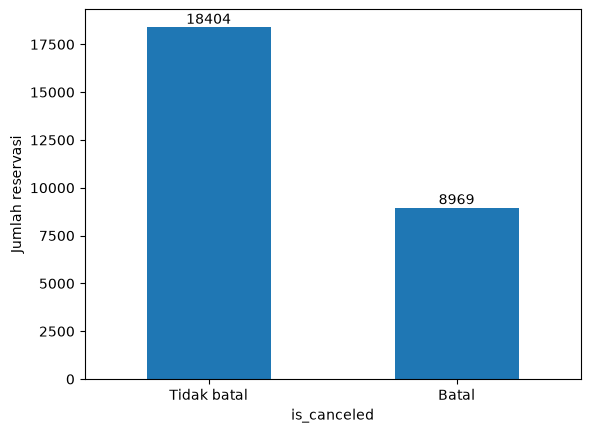

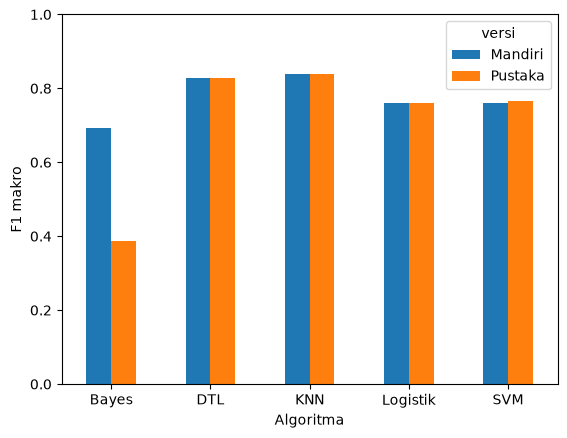

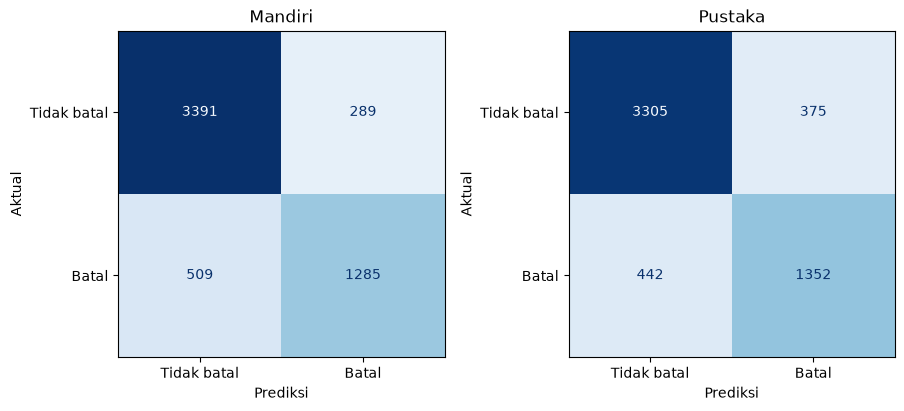

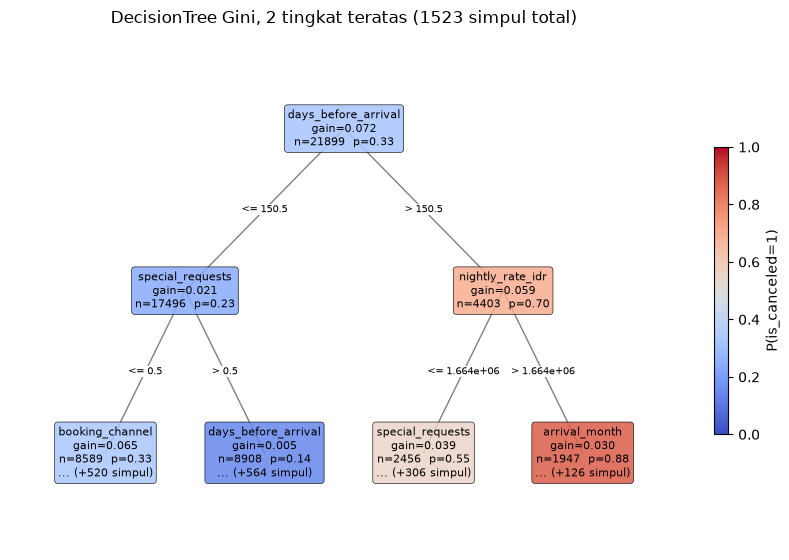

In [40]:
from src.bonus.tree_viz import plot_tree
out = Settings.OUTPUT_DIR
ax = train[TARGET].value_counts().sort_index().plot.bar(rot=0)
ax.set(xticklabels=['Tidak batal', 'Batal'], ylabel='Jumlah reservasi')
ax.bar_label(ax.containers[0])
ax.figure.savefig(out / 'laporan/gambar/gambar_1_kelas.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(ax.figure)
ax = scores.pivot(index='model', columns='versi', values='macro').plot.bar(rot=0)
ax.set(xlabel='Algoritma', ylabel='F1 makro', ylim=(0, 1))
ax.figure.savefig(out / 'laporan/gambar/gambar_2_f1.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(ax.figure)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
matrices = {version: confusion_matrix(y_val, pred, labels=[0, 1]) for version, pred in full_pred.items()}
maximum = max(int(matrix.max()) for matrix in matrices.values())
for ax, (version, matrix) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=['Tidak batal', 'Batal']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d', im_kw={'vmin': 0, 'vmax': maximum})
    ax.set(title=version, xlabel='Prediksi', ylabel='Aktual')
fig.savefig(out / 'laporan/gambar/gambar_3_kesalahan.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
levels = {col: list(values) for col, values in zip(cat_cols, prep_tree.columns_.named_transformers_['cat'].categories_)}
fig = plot_tree(tree_full, top_n=2, feature_names=prep_tree.feature_names_,
                category_levels=levels, path=out / 'laporan/gambar/gambar_4_pohon.png')
plt.show()
plt.close(fig)


## Blok E1 - Pemangkasan pohon

Model bonus di-fit pada training internal development. Calibration memilih alpha dan
check menilai hasilnya; ketiganya memisahkan grup predictor identik. Holdout final
bukan sumber pemilihan alpha atau threshold bonus.


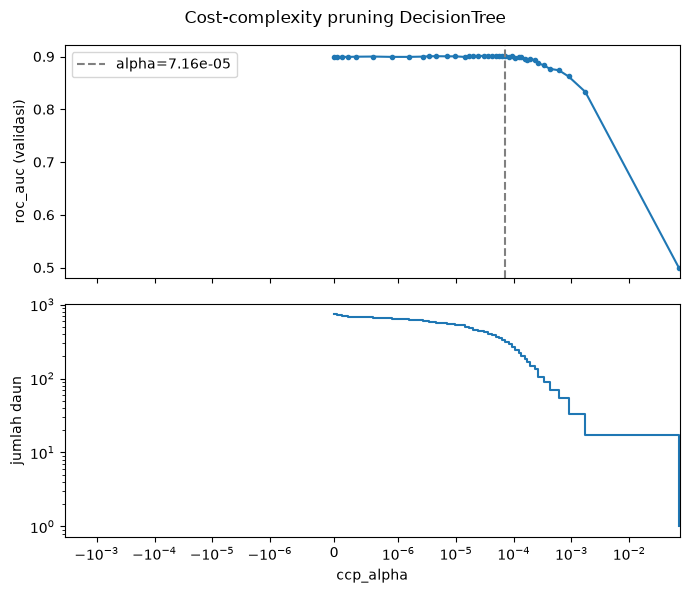

ccp_alpha      0.000072
n_leaves     311.000000
roc_auc        0.901728
Name: 23, dtype: float64

,model,accuracy,precision_positive,recall_positive,f1_positive,macro_f1,precision,recall,f1,tn,fp,fn,tp,roc_auc,pr_auc,expected_cost
0,Awal,0.847489,0.807692,0.701950,0.751118,0.820588,0.807692,0.701950,0.751118,1352,120,214,504,0.898112,0.841333,0.207306
1,Dipangkas,0.843836,0.807190,0.688022,0.742857,0.815363,0.807190,0.688022,0.742857,1354,118,224,494,0.903792,0.845869,0.210046


Pruning hanya memakai calibration/check dari development; tidak membaca holdout final.


In [41]:
from src.bonus.tree_prune import tune_ccp_alpha, plot_pruning
from sklearn.model_selection import StratifiedGroupKFold
bonus_training, bonus_validation = search.folds[0]
bonus_raw = train_set.iloc[bonus_training]
bonus_validation_raw = train_set.iloc[bonus_validation].reset_index(drop=True)
bonus_prep, bonus_tree, _ = fit_candidate(selected['Tree'], bonus_raw)
bonus_X = bonus_prep.transform(bonus_validation_raw)
bonus_y = bonus_validation_raw[TARGET].to_numpy(dtype=int)
cal, check = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=Settings.SEED).split(
    bonus_validation_raw, bonus_y, feature_groups(bonus_validation_raw)))
assert not set(feature_groups(bonus_raw)).intersection(feature_groups(bonus_validation_raw))
assert not set(feature_groups(bonus_validation_raw.iloc[cal])).intersection(feature_groups(bonus_validation_raw.iloc[check]))
pruned, pruning_path = tune_ccp_alpha(bonus_tree, bonus_X[cal], bonus_y[cal])
fig = plot_pruning(pruning_path, path=out / 'laporan/gambar/gambar_5_pemangkasan.png')
plt.show()
plt.close(fig)
best = pruning_path[pruning_path.roc_auc.round(12) == pruning_path.roc_auc.round(12).max()].iloc[-1]
display(best[['ccp_alpha', 'n_leaves', 'roc_auc']])
pruning_rows = []
for label, model in [('Awal', bonus_tree), ('Dipangkas', pruned)]:
    p = model.predict_proba(bonus_X[check])[:, 1]
    pruning_rows.append(dict(model=label, **evaluate(bonus_y[check], p)))
display(pd.DataFrame(pruning_rows))
pruning_path.to_csv(out / 'laporan/tabel/pruning_path.csv', index=False)
print('Pruning hanya memakai calibration/check dari development; tidak membaca holdout final.')


## Blok E2 - Perbandingan pengoptimasi

GD, SGD, dan Adam diuji pada data, penalti, serta batas epoch yang sama. Status converged=False berarti tolerance belum tercapai. Ini eksperimen bonus pada holdout sesudah model final dikunci, bukan pemilihan parameter submission.


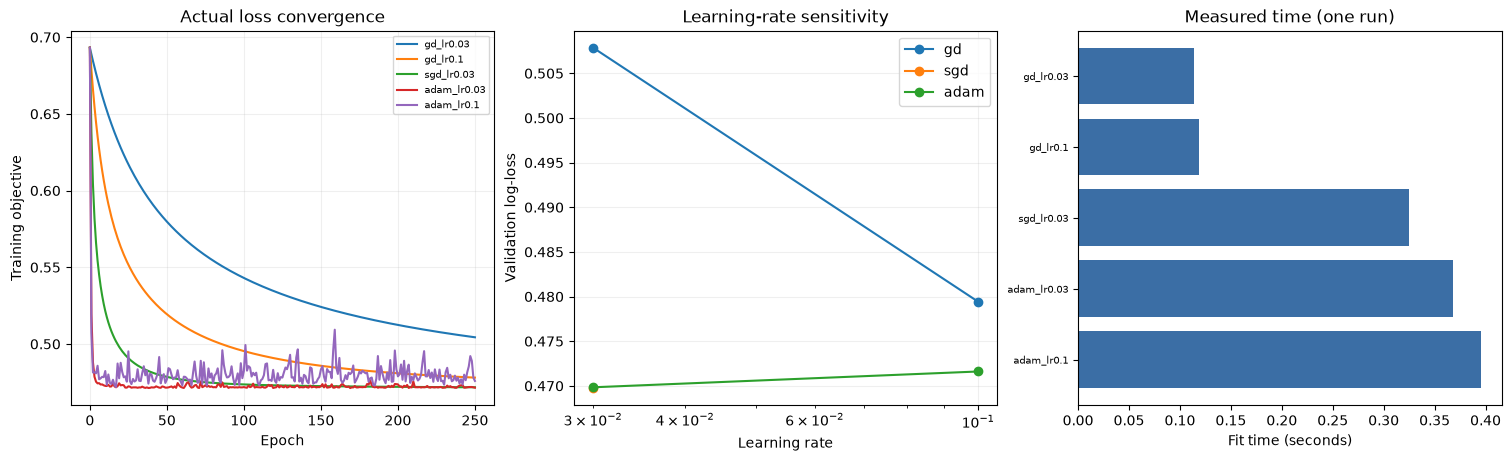

,run,epochs,converged,macro_f1,validation_log_loss
0,gd_lr0.03,250,False,0.701726,0.507869
1,gd_lr0.1,250,False,0.738676,0.479426
2,sgd_lr0.03,250,False,0.739533,0.469758
3,adam_lr0.03,250,False,0.741618,0.469841
4,adam_lr0.1,250,False,0.725695,0.471610


In [42]:
from src.bonus.logreg_optimization import compare_optimizers, plot_optimizer_comparison
opt = compare_optimizers(M[0], yt, M[1], y_val, max_iter=250, batch_size=128,
                         learning_rates={'gd': (.03,.1), 'sgd': (.03,), 'adam': (.03,.1)})
fig = plot_optimizer_comparison(opt)
fig.savefig(out/'laporan/gambar/gambar_6_optimasi.png', dpi=150)
plt.show(); plt.close(fig)
display(opt['results'][['run','epochs','converged','macro_f1','validation_log_loss']])
opt['results'].to_csv(out/'laporan/tabel/optimizer_results.csv', index=False)
opt['history'].to_csv(out/'laporan/tabel/optimizer_history.csv', index=False)


## Blok E3 - Animasi logistik

Model pendamping memakai satu fitur dan intercept tanpa penalti. Kontur dan lintasan berasal dari objective yang sama. Bingkai terakhir disimpan khusus untuk Animasi 1 pada laporan cetak.

GIF: C:\Tubes\IF3170_G35_Pistar\output\laporan\animasi\animasi_logistik.gif | video: C:\Tubes\IF3170_G35_Pistar\output\laporan\animasi\animasi_logistik.gif
Loss awal/akhir: 0.6931471805599452 0.5359766007080052
Frame: 24 | FPS: 15.0


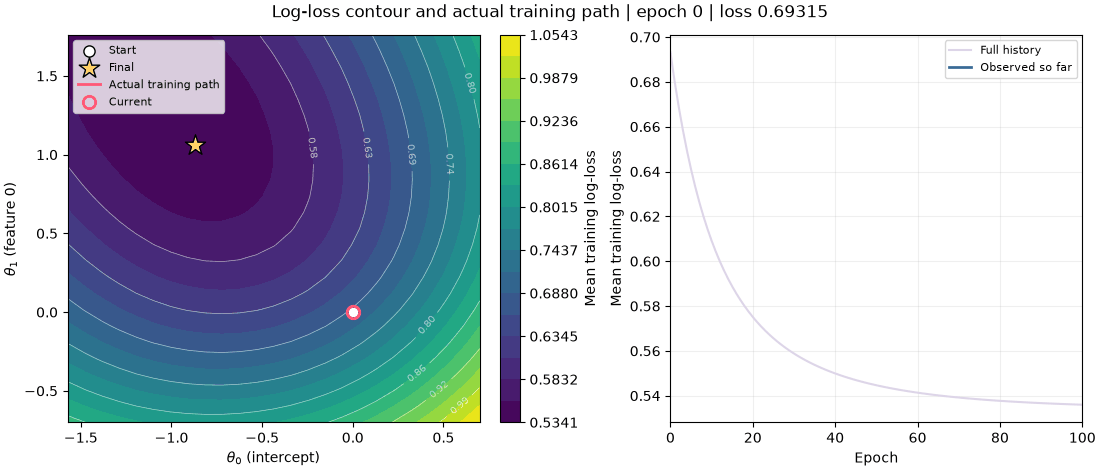

In [43]:
from src.bonus.logreg_video import make_log_loss_video
video = make_log_loss_video(M[0], yt, out / 'laporan/animasi/animasi_logistik.gif',
                            feature_index=0, max_iter=100, max_frames=24, grid_points=25)
mp4 = make_log_loss_video(M[0], yt, out/'laporan/animasi/animasi_logistik.mp4', feature_index=0,
                           max_iter=100, max_frames=24, grid_points=25)
print('GIF:', video['path'], '| video:', mp4['path'])
print('Loss awal/akhir:', video['model'].history_['train_log_loss'][0], video['model'].history_['train_log_loss'][-1])
with Image.open(video['path']) as animation:
    assert animation.n_frames == video['frames']
    animation.seek(animation.n_frames - 1)
    animation.convert('RGB').save(out / 'laporan/animasi/animasi_logistik_akhir.png')
trajectory = video['model'].parameter_history_
pd.DataFrame({'epoch': video['model'].history_['epoch'], 'theta0': trajectory[:, 0],
              'theta1': trajectory[:, 1], 'log_loss': video['model'].history_['train_log_loss']}).to_csv(out / 'laporan/tabel/animation_history.csv', index=False)
print('Frame:', video['frames'], '| FPS:', video['fps'])

display(NotebookImage(filename=str(video['path'])))


## Blok E4 - Bidang keputusan SVM

Eksperimen pendamping memakai dua fitur tertransformasi dan 400 baris training stratified.

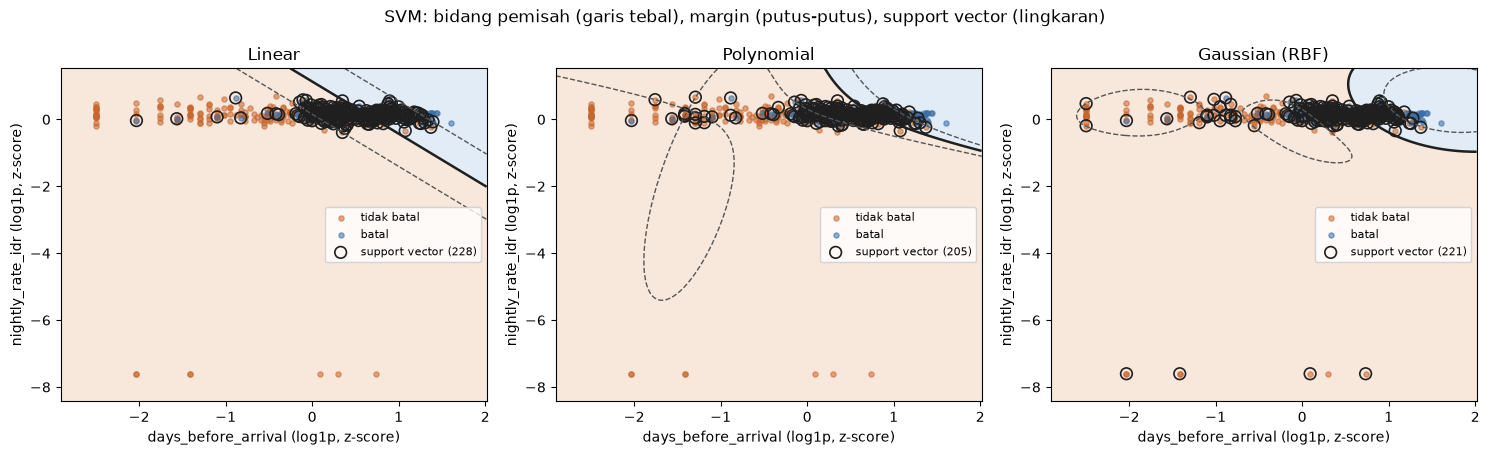

In [44]:
from src.bonus.svm_plot import plot_svm_kernels
viz, _ = train_test_split(np.arange(len(yt)), train_size=min(400, len(yt)-1),
                          stratify=yt, random_state=Settings.SEED)
transformed_names = list(small_matrix.get_feature_names_out())
viz_feature_idx = [transformed_names.index('skewed__' + col) for col in skewed_cols[:2]]
fig = plot_svm_kernels(M[0][viz][:, viz_feature_idx], yt[viz],
                       feature_names=[col + ' (log1p, z-score)' for col in skewed_cols[:2]],
                       path=out / 'laporan/gambar/gambar_7_kernel.png')
plt.show()
plt.close(fig)


## Blok E5 - Graf Bayes

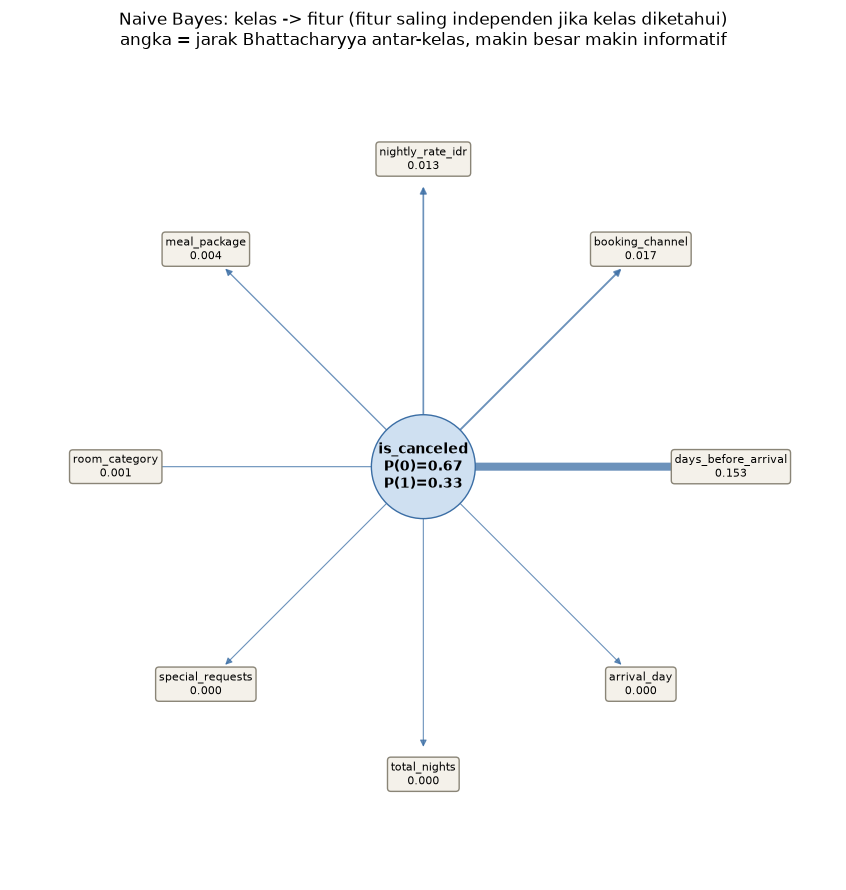

[('days_before_arrival', 0.15304038241059437), ('booking_channel', 0.017310444999146735), ('nightly_rate_idr', 0.013017765508888912)]


In [45]:
from src.bonus.naive_bayes_graph import plot_naive_bayes_graph, feature_strengths
bayes_prep, bayes, _ = fitted['optimized', 'Bayes']
fig = plot_naive_bayes_graph(bayes, bayes_prep.feature_names_, top_n=8,
                            path=out/'laporan/gambar/gambar_8_graf_bayes.png')
plt.show(); plt.close(fig)
strengths = feature_strengths(bayes, bayes_prep.feature_names_)
print(sorted(strengths.items(), key=lambda item: -item[1])[:3])


## Blok E6 - Analisis biaya

FP bernilai 2 dan FN bernilai 1. Threshold empiris dipilih pada cal, kemudian diperiksa
pada check yang terpisah. Kebijakan 2/3 merupakan acuan Bayes hanya bila peluang
merupakan posterior yang terkalibrasi; frekuensi pohon berbobot belum tentu memenuhi
asumsi itu. Hasil biaya ini tidak mengubah model atau threshold submission Kaggle.


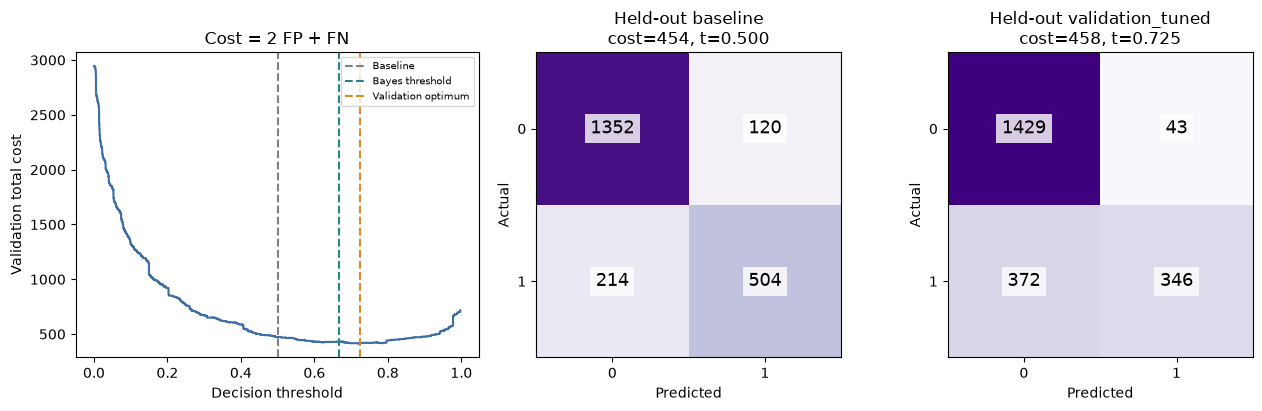

,policy,threshold,fp,fn,total_cost
3,baseline,0.500000,120,214,454.0
4,bayes,0.666667,71,285,427.0
5,validation_tuned,0.725317,43,372,458.0


Gambar 1-9, GIF, dan bingkai terakhir tersedia.


In [46]:
from src.bonus.cost_sensitive import cost_sensitive_analysis, plot_cost_sensitive
cost = cost_sensitive_analysis(bonus_tree, bonus_X[cal], bonus_y[cal],
                               bonus_X[check], bonus_y[check])
fig = plot_cost_sensitive(cost)
fig.savefig(out / 'laporan/gambar/gambar_9_biaya.png', dpi=150)
plt.show()
plt.close(fig)
display(cost['results'].query("split == 'test'")[['policy', 'threshold', 'fp', 'fn', 'total_cost']])
cost['results'].to_csv(out / 'laporan/tabel/cost_results.csv', index=False)
cost['curve'].to_csv(out / 'laporan/tabel/cost_threshold_curve.csv', index=False)
expected_figures = [out / filename for filename in (
    'laporan/gambar/gambar_1_kelas.png', 'laporan/gambar/gambar_2_f1.png', 'laporan/gambar/gambar_3_kesalahan.png',
    'laporan/gambar/gambar_4_pohon.png', 'laporan/gambar/gambar_5_pemangkasan.png', 'laporan/gambar/gambar_6_optimasi.png',
    'laporan/gambar/gambar_7_kernel.png', 'laporan/gambar/gambar_8_graf_bayes.png', 'laporan/gambar/gambar_9_biaya.png')]
for filename in expected_figures + [out / 'laporan/animasi/animasi_logistik.gif', out / 'laporan/animasi/animasi_logistik_akhir.png']:
    assert filename.is_file() and filename.stat().st_size > 0
print('Gambar 1-9, GIF, dan bingkai terakhir tersedia.')


---

# Saving and Loading Models <a name="9"></a>

---

Kelima model scratch disimpan dan dibaca ulang. Probabilitas sesudah load harus identik.


In [47]:
saved_models = {}
for name, own, lib, own_data, lib_data in models:
    model_path = own.save(Settings.OUTPUT_DIR / 'models' / (name.lower().replace('.', '') + '.pkl'))
    loaded = type(own).load(model_path)
    np.testing.assert_array_equal(own.predict_proba(own_data[1]), loaded.predict_proba(own_data[1]))
    saved_models[name] = str(model_path)
print('Save/load kelima model scratch: probabilitas identik.')


Save/load kelima model scratch: probabilitas identik.


---

# Kaggle Submission <a name="10"></a>

---

Model final berasal dari mean CV development, dengan threshold Macro F1 OOF.
Holdout dan threshold biaya FP/FN tidak menentukan pilihan submission. Seluruh baris
train.csv dipakai untuk refit, termasuk booking sah dengan ID berbeda. Preprocessing
hanya di-fit pada train. Artefak menyimpan model, preprocessor, threshold, konfigurasi,
hash input, dan versi dependency. Submission disimpan lokal; tidak ada upload otomatis.


In [48]:
# Model final dilatih ulang pada seluruh train.csv, lalu dipakai untuk memprediksi test Kaggle.
def predict_labels(bundle, frame):
    proba = bundle['model'].predict_proba(bundle['preprocessor'].transform(frame))[:, 1]
    return (proba >= bundle['threshold']).astype(int)


def json_ready(value):
    # json tidak mengenal tipe NumPy dan NaN, jadi diubah ke tipe Python biasa (NaN menjadi null).
    if isinstance(value, dict):
        return {key: json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(item) for item in value]
    if isinstance(value, np.generic):
        return json_ready(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def validate_submission(submission, sample, test):
    assert list(submission.columns) == list(sample.columns) == ['id', TARGET]
    assert len(submission) == len(sample) == len(test)
    assert submission.notna().all().all() and submission.id.is_unique and test.id.is_unique
    assert submission.id.equals(sample.id) and set(sample.id) == set(test.id)
    assert submission[TARGET].isin([0, 1]).all()


def save_final(candidate, threshold, train, test, sample, output, metadata):
    candidate = replace(candidate, max_train=None)  # submission memakai semua baris train.csv
    prep, model, timing = fit_candidate(candidate, train)
    bundle = {'preprocessor': prep, 'model': model, 'threshold': float(threshold),
              'configuration': asdict(candidate), 'metadata': json_ready(metadata), 'timing': timing}
    labels = predict_labels(bundle, test)
    by_id = pd.Series(labels, index=test.id)
    submission = pd.DataFrame({'id': sample.id, TARGET: by_id.loc[sample.id].to_numpy(dtype=int)})
    validate_submission(submission, sample, test)

    # Model yang disimpan harus memberi prediksi yang sama setelah dibaca ulang.
    pipeline_path = output / 'submission_pipeline.pkl'
    pipeline_path.write_bytes(pickle.dumps(bundle, protocol=pickle.HIGHEST_PROTOCOL))
    np.testing.assert_array_equal(labels, predict_labels(pickle.loads(pipeline_path.read_bytes()), test))

    submission.to_csv(output / 'submission.csv', index=False)
    meta = {key: value for key, value in bundle.items() if key not in ('model', 'preprocessor')}
    meta.update({'sha256': hashlib.sha256((output / 'submission.csv').read_bytes()).hexdigest(),
                 'n_train': len(train), 'n_test': len(test), 'model_class': type(model).__name__,
                 'serialization_identical': True, 'kaggle_uploaded': False})
    meta = json_ready(meta)
    (output / 'submission_metadata.json').write_text(json.dumps(meta, indent=2, allow_nan=False), encoding='utf-8')
    return submission, bundle, meta


In [49]:
import sklearn
metadata = {'seed': Settings.SEED, 'metric': 'macro_f1', 'kaggle_metric_verified': False,
            'input_sha256': input_sha256,
            'source_sha256': {str(p.relative_to(project_root)): hashlib.sha256(p.read_bytes()).hexdigest()
                              for p in sorted((project_root/'src').rglob('*.py'))},
            'python': platform.python_version(),
            'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'selection': json.loads((experiment_dir/'selection.json').read_text(encoding='utf-8')),
            'cv': cv_summary.set_index('key').loc[final_candidate.key].to_dict(),
            'holdout': holdout_scores.query("family == @final_candidate.family and phase == 'optimized' and threshold_kind == 'oof'").to_dict('records')}
submission, final_bundle, submission_metadata = save_final(
    final_candidate, final_threshold, train, test, sample_submission, out, metadata)
assert len(submission) == len(test) == 6844
assert not np.array_equal(submission[TARGET], sample_submission[TARGET])
validate_submission(submission, sample_submission, test)
submission_sha256 = submission_metadata['sha256']
print('Model:', type(final_bundle['model']).__name__, '| threshold:', final_threshold)
print('Refit:', submission_metadata['n_train'], '| submission:', len(submission), '| SHA256:', submission_sha256)
display(submission.head())


Model: KNN | threshold: 0.49
Refit: 27373 | submission: 6844 | SHA256: 25476fe0e3000e6912592a67eaf78d93efb3d1fe71aa327d64cd5358c000e0e6


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Hasil holdout berikut merupakan evaluasi setelah pemilihan model, parameter, dan
threshold dikunci. Jangan memilih ulang model berdasarkan tabel ini. Penurunan hasil
pada holdout dilaporkan apa adanya. CV untuk pemilihan model memakai threshold 0,5;
OOF tuned F1 bukan estimasi holdout. Skor leaderboard belum diketahui.
Kalibrasi SVM dengan subset dan perbedaan distribusi Gaussian/kategori Bayes
membatasi kesetaraan perbandingan dengan scikit-learn.


In [50]:
display(holdout_scores[['family','phase','threshold_kind','accuracy','macro_f1','roc_auc','pr_auc']].round(4))
selected_cv = cv_summary.set_index('key').loc[final_candidate.key]
print('Pilihan CV:', final_candidate.name, '| mean:', selected_cv.macro_f1_mean,
      '| std:', selected_cv.macro_f1_std, '| OOF threshold:', final_threshold)
p_final_holdout = fitted['optimized', final_candidate.family][2]
errors = val_set[['booking_channel']].copy()
errors['error'] = ((p_final_holdout >= final_threshold).astype(int) != y_val)
display(errors.groupby('booking_channel', dropna=False).error.agg(['count','mean']))
configuration_rows = [dict(key=c.key, balanced=c.balanced, configuration=json.dumps(asdict(c), sort_keys=True))
                       for c in search.candidates.values()]
class_balance = pd.DataFrame(configuration_rows).merge(cv_summary.drop(columns='configuration'), on='key')
class_balance.to_csv(out/'laporan/tabel/class_balance.csv', index=False)



,family,phase,threshold_kind,accuracy,macro_f1,roc_auc,pr_auc
0,Tree,baseline,default,0.8387,0.8090,0.9021,0.8392
1,Tree,baseline,oof,0.8392,0.8183,0.9021,0.8392
2,KNN,baseline,default,0.7890,0.7540,0.8404,0.7380
3,KNN,baseline,oof,0.7727,0.7479,0.8404,0.7380
4,Logistic,baseline,default,0.7903,0.7518,0.8372,0.7156
5,Logistic,baseline,oof,0.7866,0.7555,0.8372,0.7156
6,SVM,baseline,default,0.7883,0.7504,0.8397,0.7274
7,SVM,baseline,oof,0.7890,0.7603,0.8397,0.7274
8,Bayes,baseline,default,0.7638,0.6930,0.7676,0.6412
9,Bayes,baseline,oof,0.7552,0.7004,0.7676,0.6412


Pilihan CV: KNN manhattan k11 target encoding + MI weights | mean: 0.8383245352516566 | std: 0.009422030144138912 | OOF threshold: 0.49


,count,mean
booking_channel,,
Airline,12,0.250000
Complimentary,66,0.000000
Corporate,307,0.074919
Offline Agent,1586,0.087642
Online Travel Agent,3503,0.173566


## Referensi dan catatan pengumpulan

Implementasi optimizer tambahan mengacu pada [Kingma & Ba, Adam (2014/ICLR 2015)](https://arxiv.org/abs/1412.6980) dan [Parikh & Boyd, Proximal Algorithms](https://web.stanford.edu/~boyd/papers/pdf/prox_algs.pdf).
Notebook ini dilengkapi dengan bantuan Codex; bantuan implementasi/eksperimen perlu dicatat secara jujur pada Form Penggunaan Generative AI kelompok. Grafik dan tabel berasal dari run aktual, tanpa klaim skor leaderboard. Unggahan Kaggle dan penyisipan visual ke PDF laporan dilakukan oleh kelompok.
Partisi kategori biner CART mengacu pada [Hastie, Tibshirani & Friedman, ESL ?9.2.4](https://tibshirani.su.domains/ElemStatLearn.1stEd/errata/errata1.pdf).
